# PA005: High Customer Identification (Insiders)

## 0.0. Planejamento da Solução (IOT)

### Input - Entrada

1. Problema de Negócio
    - Selecionar os clientes mais valiosos para integrar um programa de Fidelização



2. Conjunto de Dados
    - Vendas de um e-commerce online, durante o período de 1 ano.

### Output - Entrada

1. A indicacao das pessoas que farão parte do programa de Insiders
   - Lista: client_id | is_insider |
     
         10323 | yes/1
     
         32413 | no/0

2. Relatório das Perguntas de Negócios
    - Quem são as pessoas elegíveis para participar do programa de insider?
    - Quantos clientes farão parte do grupo?
    - Quais as principais características desses clientes?
    - Qual a porcentagem de contribuição do faturamento, vinda do Insiders?
    - Qual a expectativa de faturamento desse grupo para os próximos meses?
    - Quais as condições para uma pessoa ser elegível ao Insiders?
    - Quais as condições para uma pessoa ser removida do Insiders?
    - Qual a garantia que o programa Insiders é melhor que o restante da base?
    - Quais ações o time de marketing pode realizar para aumentar o faturamento?   

### Task - Tarefa

1. Quem são as pessoas elegíveis para participar do programa de Insiders?
    - O que é ser elegível? O que são clientes de maior "valor"?
    - Faturamento:
        - Alto Ticket médio.
        - Alto LTV.
        - Baixa Recência.
        - Alto basket size.
        - Baixa probabilidade de Churn.
        - Alta Previsão LTV
        - Alta Propensão de compra.
         
    - Custo:
        - Baixa taxa de devolução.
          
    - Experiência de compra:
        - Média alta das avaliações
     
          
2. Quantos clientes farão parte do grupo?
    - Número total de Clientes
    - % do grupo Insiders
   
3. Quais as principais características desses clientes?
    - Escrever características do cliente:
          - Idade
          - Localização

    - Escrever características do consumo:
          - Atributos da Clusterização.    

4. Qual a porcentagem de contribuição do faturamento, vinda do Insiders?
    - Faturamento total do ano
    - Faturamento do grupo Insiders
   
5. Qual a expectativa de faturamento desse grupo para os próximos meses?
    - LTV do grupo Insiders
    - Análise de Cohort
   
6. Quais as condições para uma pessoa ser elegível ao Insiders?
    - Definir a periodicidade (1 mês, 3 meses)
    - A pessoa precisa ser similar ou parecida com uma pessoa do grupo.

7. Quais as condições para uma pessoa ser removida do Insiders?
    - Definir a periodicidade (1 mês, 3 meses)
    - A pessoa precisa ser dissimilar ou não parecida com uma pessoa do grupo.

8. Qual a garantia que o programa Insiders é melhor que o restante da base?
    - Teste A/B
    - Teste A/B Baysiano
    - Teste de Hipóteses
   
9. Quais ações o time de marketing pode realizar para aumentar o faturamento?
    - Desconto
    - Preferência de Compra
    - Frete
    - Visita a empresa

# 0.0. Imports

In [1]:
#!pip install ydata-profiling

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import regex as re

import umap.umap_ as umap

from matplotlib import pyplot as plt
from IPython.display import HTML

from ydata_profiling import ProfileReport

from sklearn import cluster as c
from sklearn import metrics as m
from sklearn import preprocessing as pp
from sklearn import decomposition as dd
from sklearn.manifold import TSNE
from sklearn import mixture as mx
from scipy.cluster import hierarchy as hc

from plotly import express as px

from yellowbrick.cluster import KElbowVisualizer, SilhouetteVisualizer

/tmp/ipykernel_1026/311933212.py:11: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport


## 0.1. Helper Functions

In [3]:
def jupyter_settings():
    %matplotlib inline
    %pylab inline
    
    plt.style.use( 'ggplot' )
    plt.rcParams['figure.figsize'] = [24, 9]
    plt.rcParams['font.size'] = 24
    
    display( HTML( '<style>.container { width:100% !important; }</style>') )
    pd.options.display.max_columns = None
    pd.options.display.max_rows = None
    pd.set_option( 'display.expand_frame_repr', False )
    
    sns.set()

jupyter_settings()

%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib


## 0.2. Load dataset

In [4]:
# load data
df_raw = pd.read_csv( '../data/raw/Ecommerce.csv', encoding='ISO-8859-1')

# drop extra column
df_raw.drop( columns=['Unnamed: 8'], axis=1, inplace = True)

In [5]:
df_raw.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,29-Nov-16,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,29-Nov-16,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,29-Nov-16,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,29-Nov-16,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,29-Nov-16,3.39,17850.0,United Kingdom


#  <font color='red'> 1.0. Descrição dos Dados </font>

In [6]:
df1 = df_raw.copy()

## 1.1. Rename Columns

In [7]:
df1.columns

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='object')

In [8]:
cols_new = ['invoice_no', 'stock_code', 'description', 'quantity', 'invoice_date', 'unit_price', 'customer_id', 'country']
df1.columns = cols_new

## 1.2. Data Dimensions

In [9]:
print( 'Number of rows: {}'.format( df1.shape[0] ) )
print( 'Number of cols: {}'.format( df1.shape[1] ) )

Number of rows: 541909
Number of cols: 8


## 1.3. Data Types

In [10]:
df1.dtypes

invoice_no       object
stock_code       object
description      object
quantity          int64
invoice_date     object
unit_price      float64
customer_id     float64
country          object
dtype: object

## 1.4. Check NA

In [11]:
df1.isna().sum()

invoice_no           0
stock_code           0
description       1454
quantity             0
invoice_date         0
unit_price           0
customer_id     135080
country              0
dtype: int64

## 1.5. Replace NA

In [12]:
df_missing = df1.loc[df1['customer_id'].isna(), :]
df_not_missing = df1.loc[~df1['customer_id'].isna(), :]

In [13]:
# create reference
df_backup = pd.DataFrame( df_missing['invoice_no'].drop_duplicates() )
df_backup['customer_id'] = np.arange(19000, 19000 + len(df_backup), 1)

# merge original with reference dataframe
df1 = pd.merge(df1, df_backup, how='left', on='invoice_no')

# coalesce
df1['customer_id'] = df1['customer_id_x'].combine_first(df1['customer_id_y'])

# drop extra columns
df1 = df1.drop(columns=['customer_id_x', 'customer_id_y'], axis=1)

In [14]:
df1.isna().sum()

invoice_no         0
stock_code         0
description     1454
quantity           0
invoice_date       0
unit_price         0
country            0
customer_id        0
dtype: int64

## 1.6. Change dtypes

In [15]:
df1.dtypes

invoice_no       object
stock_code       object
description      object
quantity          int64
invoice_date     object
unit_price      float64
country          object
customer_id     float64
dtype: object

In [16]:
# invoice_date
df1['invoice_date'] = pd.to_datetime( df1['invoice_date'], format='%d-%b-%y' )

# customer_id
df1['customer_id'] = df1['customer_id'].astype(int)

df1.head()

,invoice_no,stock_code,description,quantity,invoice_date,unit_price,country,customer_id
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2016-11-29,2.55,United Kingdom,17850
1,536365,71053,WHITE METAL LANTERN,6,2016-11-29,3.39,United Kingdom,17850
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2016-11-29,2.75,United Kingdom,17850
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2016-11-29,3.39,United Kingdom,17850
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2016-11-29,3.39,United Kingdom,17850


## 1.7. Descriptive Statistics

In [17]:
num_attributes = df1.select_dtypes( include=['int64', 'float64'] )
cat_attributes = df1.select_dtypes( exclude=['int64', 'float64', 'datetime64[ns]'])

### 1.7.1. Numerical Attributes

In [18]:
# Central tendency - mean, median
ct1 = pd.DataFrame( num_attributes.apply( np.mean ) ).T
ct2 = pd.DataFrame( num_attributes.apply( np.median ) ).T

# Dispersion - desvio padrão, min, max, range, std, skew, kurtosis
d1 = pd.DataFrame( num_attributes.apply( np.std ) ).T
d2 = pd.DataFrame( num_attributes.apply( np.min ) ).T
d3 = pd.DataFrame( num_attributes.apply( np.max ) ).T
d4 = pd.DataFrame( num_attributes.apply( lambda x: x.max() - x.min() ) ).T
d5 = pd.DataFrame( num_attributes.apply( lambda x: x.skew() ) ).T
d6 = pd.DataFrame( num_attributes.apply( lambda x: x.kurtosis() ) ).T

# concatenate
m1 = pd.concat( [d2, d3, d4, ct1, ct2, d1, d5, d6] ).T.reset_index()
m1.columns = ['attributes', 'min', 'max', 'range', 'mean', 'mediana', 'std', 'skew', 'kurtosis']
m1

,attributes,min,max,range,mean,mediana,std,skew,kurtosis
0,quantity,-80995.00,80995.0,161990.00,9.552250,3.00,218.080957,-0.264076,119769.160031
1,unit_price,-11062.06,38970.0,50032.06,4.611114,2.08,96.759764,186.506972,59005.719097
2,customer_id,12346.00,22709.0,10363.00,16688.840453,16249.00,2911.408666,0.487449,-0.804287


### <font color='red'> 1.7.1.1. Numerical Attributes - Investigating </font>

1. Quantity negativa ( pode ser devolucao )
2. Preço unitário igual a zero ( pode ser promocao )

### 1.7.2. Categorical Attributes

In [19]:
cat_attributes.head()

,invoice_no,stock_code,description,country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,United Kingdom
1,536365,71053,WHITE METAL LANTERN,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,United Kingdom


<b>invoice_no</b>

In [20]:
# Problema: Temos invoice com letras e numeros
# df1['invoice_no'].astype( int )

# identificacao
df_letter_invoices = df1.loc[df1['invoice_no'].apply( lambda x: bool( re.search( '[^0-9]+', x) ) ), :]
df_letter_invoices.head()

print( 'Total number of invoices: {}'.format( len( df_letter_invoices )))
print( 'Total number of negative quantity: {}'.format( len( df_letter_invoices[ df_letter_invoices['quantity'] < 0 ] )))

#len( cat_attributes.loc[cat_attributes['invoice_no'].apply( lambda x: bool( re.search( '[^0-9]+', x) ) ), 'invoice_no'].drop_duplicates() )

Total number of invoices: 9291
Total number of negative quantity: 9288


<b>stock_code</b>

In [21]:
#check stock codes only characteres 
df1.loc[cat_attributes['stock_code'].apply( lambda x: bool( re.search( '^[a-zA-Z]+$', x) ) ), 'stock_code'].unique()

# Ação:
## 1. Remove stock_code in ['POST', 'D', 'M', 'PADS', 'DOT', 'CRUK']

array(['POST', 'D', 'DOT', 'M', 'S', 'AMAZONFEE', 'm', 'DCGSSBOY',
       'DCGSSGIRL', 'PADS', 'B', 'CRUK'], dtype=object)

<b>description</b>

In [22]:
df1.head()

# Ação: Delete description

,invoice_no,stock_code,description,quantity,invoice_date,unit_price,country,customer_id
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2016-11-29,2.55,United Kingdom,17850
1,536365,71053,WHITE METAL LANTERN,6,2016-11-29,3.39,United Kingdom,17850
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2016-11-29,2.75,United Kingdom,17850
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2016-11-29,3.39,United Kingdom,17850
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2016-11-29,3.39,United Kingdom,17850


<b>country</b>

In [23]:
len( df1['country'].unique() )

38

In [24]:
df1['country'].value_counts( normalize=True )

country
United Kingdom          0.914320
Germany                 0.017521
France                  0.015790
EIRE                    0.015124
Spain                   0.004674
Netherlands             0.004375
Belgium                 0.003818
Switzerland             0.003694
Portugal                0.002803
Australia               0.002323
Norway                  0.002004
Italy                   0.001482
Channel Islands         0.001399
Finland                 0.001283
Cyprus                  0.001148
Sweden                  0.000853
Unspecified             0.000823
Austria                 0.000740
Denmark                 0.000718
Japan                   0.000661
Poland                  0.000629
Israel                  0.000548
USA                     0.000537
Hong Kong               0.000531
Singapore               0.000423
Iceland                 0.000336
Canada                  0.000279
Greece                  0.000269
Malta                   0.000234
United Arab Emirates    0.000125
Eu

In [25]:
df1[['customer_id', 'country']].drop_duplicates().groupby( 'country' ).count().reset_index().sort_values( 'customer_id', ascending = False)

,country,customer_id
36,United Kingdom,7587
14,Germany,95
13,France,90
10,EIRE,44
31,Spain,31
3,Belgium,25
33,Switzerland,24
27,Portugal,20
19,Italy,15
16,Hong Kong,15


#  <font color='red'> 2.0. Filtragem de Variáveis</font>

In [26]:
df2 = df1.copy()

In [27]:
df2.dtypes

invoice_no              object
stock_code              object
description             object
quantity                 int64
invoice_date    datetime64[ns]
unit_price             float64
country                 object
customer_id              int64
dtype: object

In [28]:
# === Numerical Attributes ======

# unit price > 0.0
df2 = df2.loc[df2['unit_price'] >= 0.04, :]

# === Categorical Attributes ===
df2 = df2[~df2['stock_code'].isin( ['POST', 'D', 'DOT', 'M', 'S', 'AMAZONFEE', 'm', 'DCGSSBOY', 'DCGSSGIRL', 'PADS', 'B', 'CRUK'] )]

# description
df2 = df2.drop( columns='description', axis=1)

# map
df2 = df2[~df2['country'].isin( ['European Community', 'Unspecified'] )]

# bad users
df2 = df2[~df2['customer_id'].isin( [16446])]

## quantity - Negative numbers means products returns
df2_returns = df2.loc[df2['quantity'] < 0, :]
df2_purchases = df2.loc[df2['quantity'] >= 0, :]

#  <font color='red'> 3.0. Feature Engeneering </font>

In [29]:
df3 = df2.copy()

## 3.1. Feature Creation

In [30]:
# data reference
df_ref = df3.drop( ['invoice_no', 'stock_code', 'quantity', 'invoice_date', 'unit_price',
                    'country'], axis=1 ).drop_duplicates( ignore_index = True)

In [31]:
df_ref.head(10)

,customer_id
0,17850
1,13047
2,12583
3,13748
4,15100
5,15291
6,14688
7,17809
8,15311
9,16098


### 3.1.1. Gross Revenue

In [32]:
# Gross Revenue (Faturamento) quanity * price = Faturamento
df2_purchases.loc[:, 'gross_revenue'] = df2_purchases.loc[:, 'quantity'] * df2_purchases.loc[:, 'unit_price']

# Monetary
df_monetary = df2_purchases.loc[:, ['customer_id', 'gross_revenue']].groupby( 'customer_id' ).sum().reset_index()
df_ref = pd.merge( df_ref, df_monetary, on='customer_id', how='left')
df_ref.isna().sum()

/tmp/ipykernel_1026/204081654.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df2_purchases.loc[:, 'gross_revenue'] = df2_purchases.loc[:, 'quantity'] * df2_purchases.loc[:, 'unit_price']


customer_id       0
gross_revenue    91
dtype: int64

### 3.1.2. Recency - Day from last purchase

In [33]:
# Recency
df_recency = df2_purchases[['customer_id', 'invoice_date']].groupby( 'customer_id' ).max().reset_index()
df_recency['recency_days'] = ( df3['invoice_date'].max() - df_recency['invoice_date'] ).dt.days
df_recency = df_recency[['customer_id', 'recency_days']].copy()
df_ref = pd.merge( df_ref, df_recency, on='customer_id', how='left' )
df_ref.isna().sum()

customer_id       0
gross_revenue    91
recency_days     91
dtype: int64

### 3.1.3. Quantity of purchased  (não utilzada mais)

In [34]:
## Número de produtos
#df_freq = ( df2_purchases[['customer_id', 'invoice_no']].drop_duplicates().groupby( 'customer_id' ).count().reset_index()
#                                                        .rename( columns={'invoice_no': 'qtde_invoices'}) )
#df_ref = pd.merge( df_ref, df_freq, on='customer_id', how='left' )
#df_ref.isna().sum()

### 3.1.4. Quantity of items purchased  (não utilizada mais)

In [35]:
## Número de produtos
#df_freq = ( df2_purchases[['customer_id', 'quantity']].groupby( 'customer_id' ).sum().reset_index()
#                                                        .rename( columns={'quantity': 'qtde_items' }) )
#df_ref = pd.merge( df_ref, df_freq, on='customer_id', how='left' )
#df_ref.isna().sum()

### 3.1.4. Quantity of products purchased

In [36]:
# Número de produtos
df_qtde = ( df2_purchases[['customer_id', 'stock_code']].groupby( 'customer_id' ).count().reset_index()
                                                          .rename( columns={'stock_code': 'qtde_products' }) )
df_ref = pd.merge( df_ref, df_qtde, on='customer_id', how='left' )
df_ref.isna().sum()

customer_id       0
gross_revenue    91
recency_days     91
qtde_products    91
dtype: int64

### 3.1.5. Average Ticket Value  (não utilizada mais)

In [37]:
# Avg ticket
#df_avg_ticket = df2_purchases[['customer_id', 'gross_revenue']].groupby( 'customer_id' ).mean().reset_index().rename(columns={'gross_revenue':'avg_ticket'})
#df_ref = pd.merge( df_ref, df_avg_ticket, on='customer_id', how='left')
#df_ref.isna().sum()

### 3.1.6. Average Recency Days  (não utilizada mais)

In [38]:
#df_aux = df2[['customer_id', 'invoice_date']].drop_duplicates().sort_values( ['customer_id', 'invoice_date'], ascending=[True, True] ) 
#df_aux['next_customer_id'] = df_aux['customer_id'].shift() # next customer
#df_aux['previous_date'] = df_aux['invoice_date'].shift() # previous invoice date 
#
#df_aux['avg_recency_days'] = df_aux.apply(lambda x: ( x['invoice_date'] - x['previous_date']).days if x['customer_id'] == x['next_customer_id'] else np.nan, axis=1)
#
#df_aux = df_aux.drop( ['invoice_date', 'next_customer_id', 'previous_date'], axis=1).dropna()
#
## average recency
#df_avg_recency_days = df_aux.groupby( 'customer_id' ).mean().reset_index()
#
## merge
#df_ref = pd.merge( df_ref, df_avg_recency_days, on='customer_id', how='left')
#df_ref.isna().sum()


### 3.1.7. Frequency Purchase

In [39]:
df_aux = ( df2[['customer_id', 'invoice_no', 'invoice_date']].drop_duplicates()
                                                            .groupby( 'customer_id' )
                                                            .agg( max_ = ( 'invoice_date', 'max' ),
                                                                  min_ = ( 'invoice_date', 'min' ),
                                                                  days_ = ( 'invoice_date', lambda x: ((x.max() - x.min()).days ) + 1 ),
                                                                  buy_ = ( 'invoice_no', 'count') ) ).reset_index()                                                               

# Frequency
df_aux['frequency'] = df_aux[['buy_', 'days_']].apply( lambda x: x['buy_'] / x['days_'] if x['days_'] != 0 else 0, axis = 1)

# Merge
df_ref = pd.merge(df_ref, df_aux[['customer_id', 'frequency']], on='customer_id', how='left')
df_ref.isna().sum()

customer_id       0
gross_revenue    91
recency_days     91
qtde_products    91
frequency         0
dtype: int64

In [40]:
df_aux.sort_values( 'frequency', ascending=False ).head()

,customer_id,max_,min_,days_,buy_,frequency
2777,16120,2017-10-09,2017-10-09,1,5,5.0
2020,15098,2017-06-08,2017-06-08,1,4,4.0
2687,16000,2017-12-05,2017-12-05,1,3,3.0
2635,15920,2017-07-06,2017-07-06,1,3,3.0
3812,17545,2017-10-25,2017-10-25,1,3,3.0


### 3.1.8. Number of Returns

In [41]:
# returns
df_returns = df2_returns[['customer_id', 'quantity']].groupby( 'customer_id' ).sum().reset_index().rename( columns={'quantity':'qtde_returns'})
df_returns['qtde_returns'] = df_returns['qtde_returns'] * -1
df_ref = pd.merge( df_ref, df_returns, on='customer_id', how='left' )

df_ref.loc[df_ref['qtde_returns'].isna(), 'qtde_returns'] = 0

df_ref.isna().sum()


customer_id       0
gross_revenue    91
recency_days     91
qtde_products    91
frequency         0
qtde_returns      0
dtype: int64

### 3.1.9. Basket Size - Quantidade de Itens por Cesta (Quantity)   (não utilizada mais)

- Invoice No = Compra = purchase
- Stock Code = Produto = Product
- Quantity = Item = Item

In [42]:
#df_aux = ( df2_purchases.loc[:, ['customer_id', 'invoice_no', 'quantity']].groupby( 'customer_id' )
#                                                            .agg( n_purchase=( 'invoice_no', 'nunique'),
#                                                                  n_products=( 'quantity', 'sum') )
#                                                            .reset_index() )
#
## calculation
#df_aux['avg_basket_size'] = df_aux['n_products'] / df_aux['n_purchase']
#
## merge
#df_ref = pd.merge( df_ref, df_aux[['customer_id', 'avg_basket_size']], how='left', on='customer_id')
#
#df_ref.isna().sum()

### 3.1.10. Unique Basket Size - Quantidade de produtos distinto por compra (não utilizada mais)

In [43]:
#f_aux = ( df2_purchases.loc[:, ['customer_id', 'invoice_no', 'stock_code']].groupby( 'customer_id' )
#                                                            .agg( n_purchase=( 'invoice_no', 'nunique'),
#                                                                  n_products=( 'stock_code', 'nunique') )
#                                                            .reset_index() )
#
## calculation
#df_aux['avg_unique_basket_size'] = df_aux['n_products'] / df_aux['n_purchase']
#
## merge
#df_ref = pd.merge( df_ref, df_aux[['customer_id', 'avg_unique_basket_size']], how='left', on='customer_id')
#
#df_ref.isna().sum()

#  <font color='red'> 4.0. EDA ( Exploratory Data Analysis )</font>

In [44]:
df4 = df_ref.dropna()
df4.isna().sum()

customer_id      0
gross_revenue    0
recency_days     0
qtde_products    0
frequency        0
qtde_returns     0
dtype: int64

## 4.1. Univariate Analysis

**Notes**
1. Clusters Coesos - Separados
2. Metricas
    - Min, Máximo, Range (Dispersão)
    - Média e Mediana
    - Desvio Padrão e Variância
    - Coeficiente de Variação (CV)
    - Distribuição

In [45]:
profile = ProfileReport( df4 )
profile.to_file( 'output.html' )

/home/gabri/miniconda3/envs/pa005/lib/python3.10/site-packages/ydata_profiling/utils/dataframe.py:137: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.rename(columns={"index": "df_index"}, inplace=True)


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|███████████████████████████████████████████████████████████████████████████████████| 6/6 [00:00<00:00, 196.19it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

### 4.1.1. Gross Revenue

In [46]:
df4.sort_values('gross_revenue', ascending=False).head(10)

,customer_id,gross_revenue,recency_days,qtde_products,frequency,qtde_returns
1017,14646,279138.02,1.0,2060.0,0.206215,288.0
492,18102,259657.30,0.0,431.0,0.163043,0.0
433,17450,194550.79,8.0,337.0,0.136111,952.0
66,14911,140450.72,1.0,5673.0,0.651475,3332.0
1150,12415,124564.53,24.0,713.0,0.076433,427.0
190,14156,117379.63,9.0,1400.0,0.178571,859.0
15,17511,91062.38,2.0,963.0,0.120968,1535.0
1381,12346,77183.60,325.0,1.0,2.000000,74215.0
12,16029,72882.09,38.0,241.0,0.196429,8004.0
955,16684,66653.56,4.0,277.0,0.084507,864.0


In [47]:
np.sum( df3.loc[df3['customer_id'] == 14646, 'quantity'] * df3.loc[df3['customer_id'] == 14646, 'unit_price'] )

278778.02

### 4.1.2. Qtde Items

In [48]:
#df4[df4['qtde_items'] == 196844]

In [49]:
df3[df3['customer_id'] == 14646].sort_values('quantity', ascending=False).head(30)

,invoice_no,stock_code,quantity,invoice_date,unit_price,country,customer_id
421601,573003,23084,2400,2017-10-25,2.08,Netherlands,14646
409248,572052,22595,1728,2017-10-18,0.72,Netherlands,14646
63444,541570,21212,1440,2017-01-17,0.42,Netherlands,14646
534952,581175,23084,1440,2017-12-05,1.79,Netherlands,14646
186820,552883,21212,1200,2017-05-10,0.42,Netherlands,14646
204198,554642,22243,960,2017-05-23,1.45,Netherlands,14646
137027,548011,22630,640,2017-03-27,1.65,Netherlands,14646
137026,548011,22629,640,2017-03-27,1.65,Netherlands,14646
454041,575508,22492,576,2017-11-08,0.55,Netherlands,14646
408892,572035,22492,576,2017-10-18,0.55,Netherlands,14646


### 4.1.3. Qtde Products

In [50]:
df4[df4['qtde_products'] == 7838]

,customer_id,gross_revenue,recency_days,qtde_products,frequency,qtde_returns
68,17841,40967.72,1.0,7838.0,0.453083,203.0


### 4.1.4. Avg Ticket

In [51]:
#df4[df4['avg_ticket'] == 56157.5]

In [52]:
#df3[df3['customer_id'] == 16446]

### 4.1.5. Frequency

In [53]:
df4[df4['frequency'] > 2]

,customer_id,gross_revenue,recency_days,qtde_products,frequency,qtde_returns
3630,15098,39916.50,182.0,3.0,4.0,60.0
3963,15920,163.55,154.0,58.0,3.0,0.0
3972,18024,389.78,152.0,21.0,3.0,36.0
4976,16120,1309.14,59.0,30.0,5.0,12.0
5209,17545,645.96,43.0,145.0,3.0,0.0
5576,18139,8438.34,17.0,159.0,3.0,0.0
5765,16000,12393.70,2.0,9.0,3.0,0.0


### 4.1.6. Avg Basket Size

In [54]:
#df4[df4['avg_basket_size'] == 40498.5]

## 4.2. Bivariate Analysis

In [55]:
# original dataset
#df43 = df4.drop( columns=['customer_id'], axis=1 ).copy()

# selected dataset
cols_selected = ['customer_id', 'gross_revenue', 'recency_days', 'qtde_products', 'frequency', 'qtde_returns']
df43 = df4[cols_selected].drop( columns='customer_id', axis=1 ).copy()


<Figure size 2500x1200 with 0 Axes>

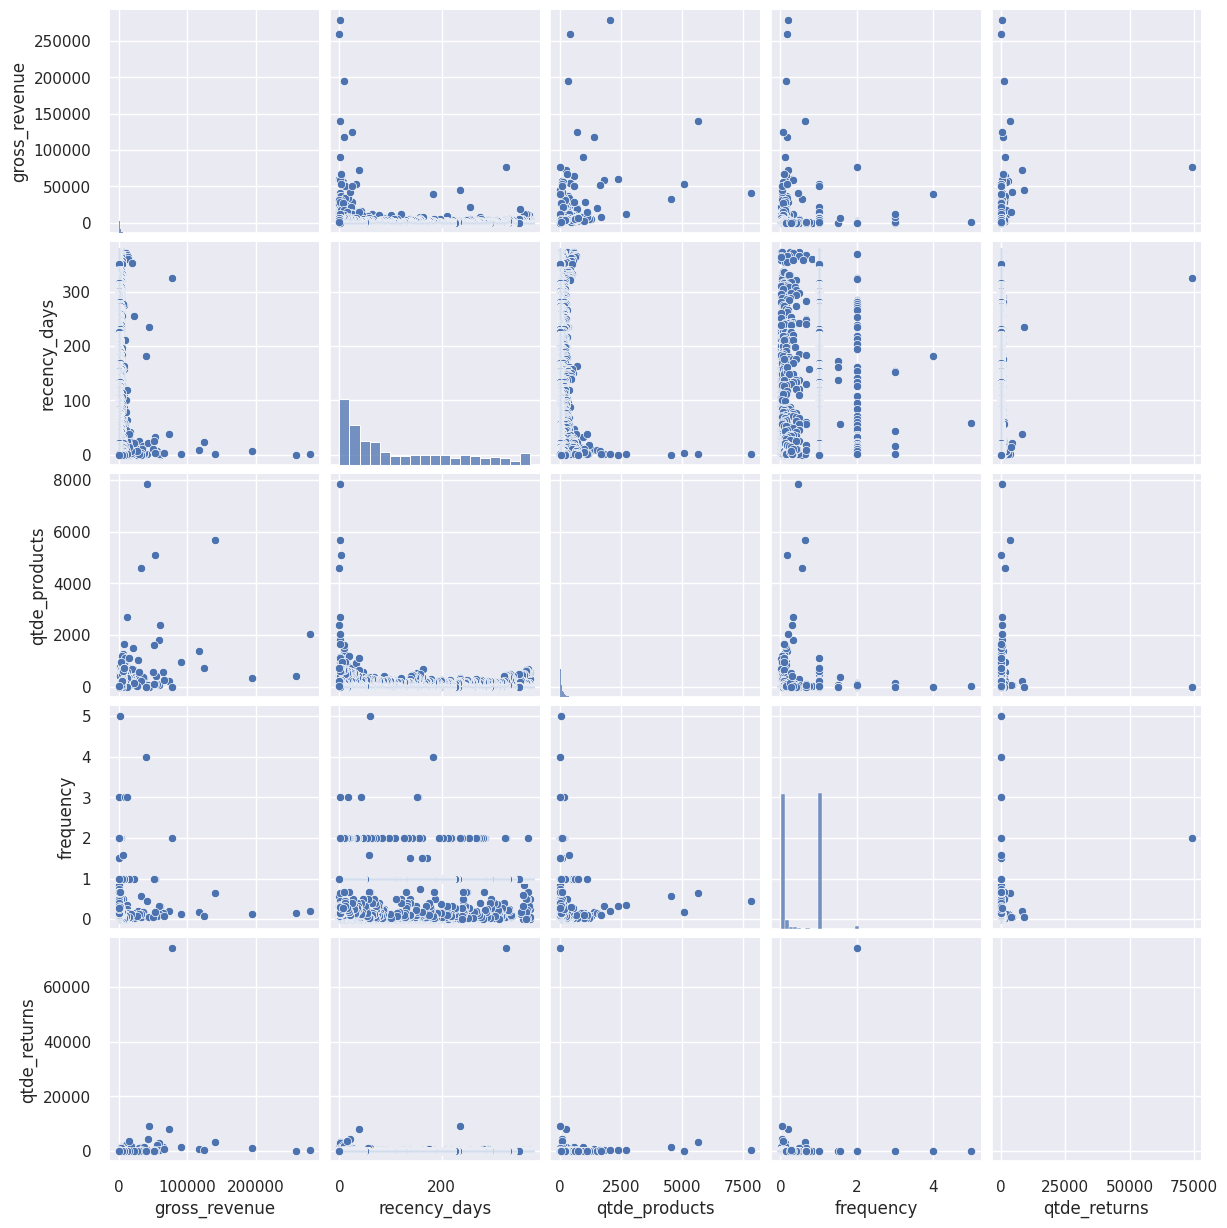

In [56]:
plt.figure( figsize=(25,12) )
sns.pairplot( df43 )

**Notes**

  1. Frequency has low variance


## 4.3. Estudo do Espaço

In [57]:
# original dataset
#df43 = df4.drop( columns=['customer_id'], axis=1 ).copy()

# selected dataset
cols_selected = ['customer_id', 'gross_revenue', 'recency_days', 'qtde_products', 'frequency', 'qtde_returns']
df43 = df4[cols_selected].drop( columns='customer_id', axis=1 ).copy()

In [58]:
mm = pp.MinMaxScaler()

df43['gross_revenue'] = mm.fit_transform( df43[['gross_revenue']] )
df43['recency_days'] = mm.fit_transform( df43[['recency_days']] )
#df43['qtde_invoices'] = mm.fit_transform( df43[['qtde_invoices']] )
#df43['qtde_items'] = mm.fit_transform( df43[['qtde_items']] )
df43['qtde_products'] = mm.fit_transform( df43[['qtde_products']] )
#df43['avg_ticket'] = mm.fit_transform( df43[['avg_ticket']] )
#df43['avg_recency_days'] = mm.fit_transform( df43[['avg_recency_days']] )
df43['frequency'] = mm.fit_transform( df43[['frequency']] )
df43['qtde_returns'] = mm.fit_transform( df43[['qtde_returns']] )
#df43['avg_basket_size'] = mm.fit_transform( df43[['avg_basket_size']] )
#df43['avg_unique_basket_size'] = mm.fit_transform( df43[['avg_unique_basket_size']] )

X = df43.copy()

In [59]:
X.head()

,gross_revenue,recency_days,qtde_products,frequency,qtde_returns
0,0.019312,0.997319,0.037770,0.096237,0.000539
1,0.011579,0.150134,0.021692,0.008676,0.000472
2,0.024020,0.005362,0.029476,0.008059,0.000674
3,0.003396,0.254692,0.003445,0.002497,0.000000
4,0.003137,0.892761,0.000255,0.026211,0.000296


### 4.3.1. PCA

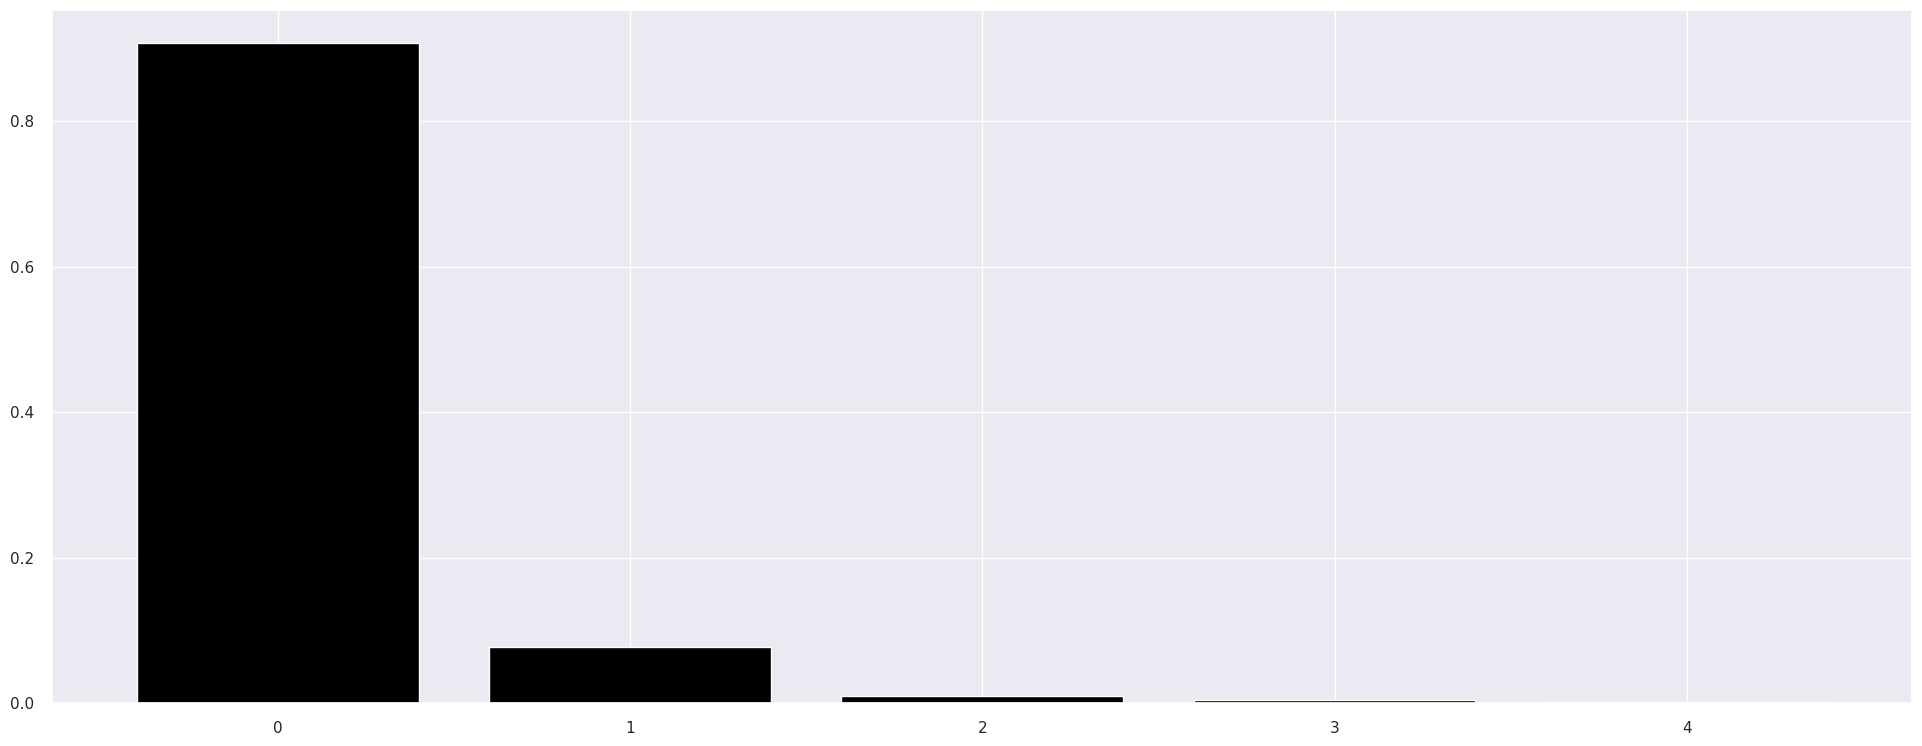

In [60]:
pca = dd.PCA( n_components=X.shape[1] )

principal_components = pca.fit_transform(X)

# plot explained variable
features = range( pca.n_components_ )

plt.bar( features, pca.explained_variance_ratio_, color='black')

# pca component
df_pca = pd.DataFrame( principal_components )

<Axes: xlabel='0', ylabel='1'>

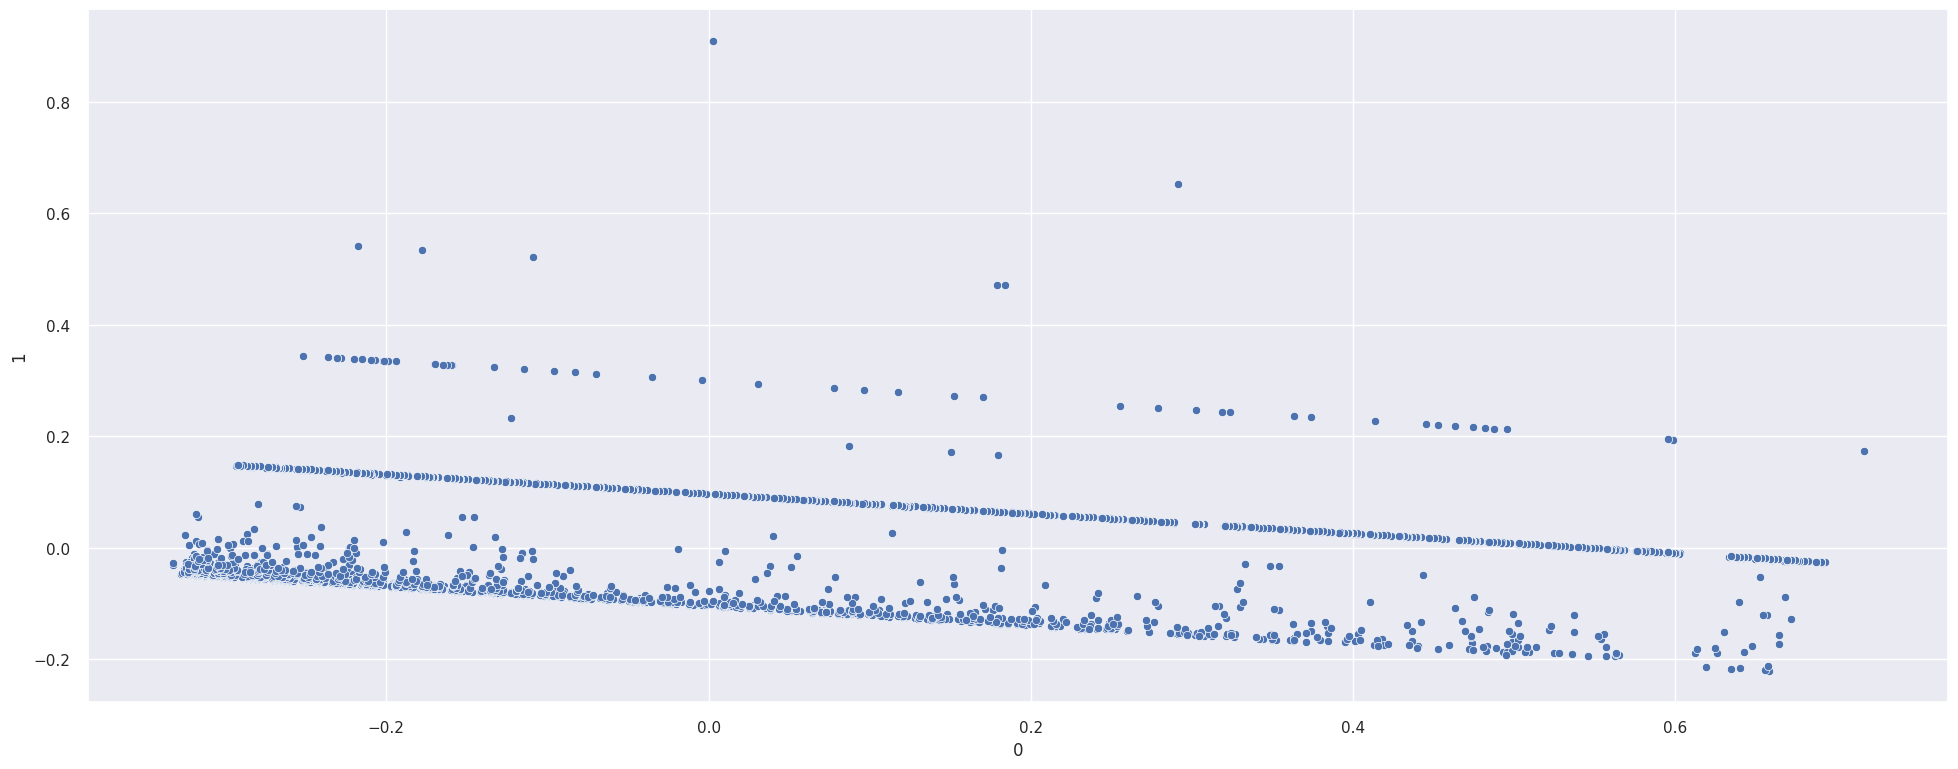

In [61]:
sns.scatterplot( x=0, y=1, data=df_pca)

### 4.3.2. UMAP

/home/gabri/miniconda3/envs/pa005/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


<Axes: xlabel='embedding_x', ylabel='embedding_y'>

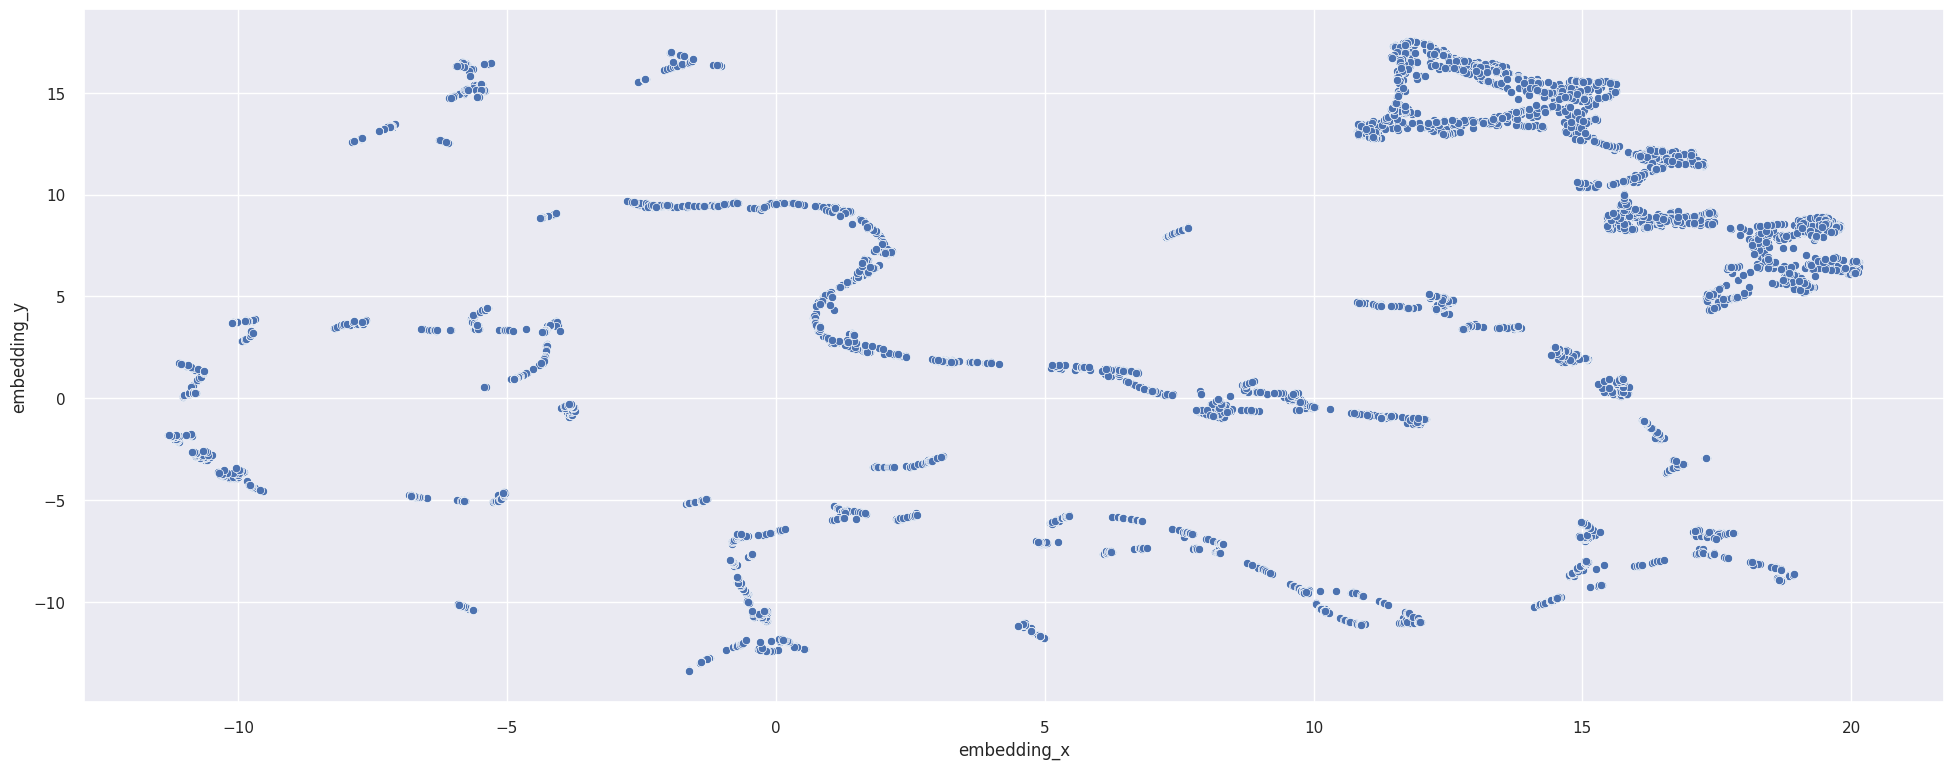

In [62]:
reducer = umap.UMAP( random_state=42 )
embedding = reducer.fit_transform( X )

# embedding
df_umap = pd.DataFrame()
df_umap['embedding_x'] = embedding[:, 0]
df_umap['embedding_y'] = embedding[:, 1]

# plot UMAP
sns.scatterplot( x='embedding_x', y='embedding_y', data=df_umap )

### 4.3.3. t-SNE

<Axes: xlabel='embedding_x', ylabel='embedding_y'>

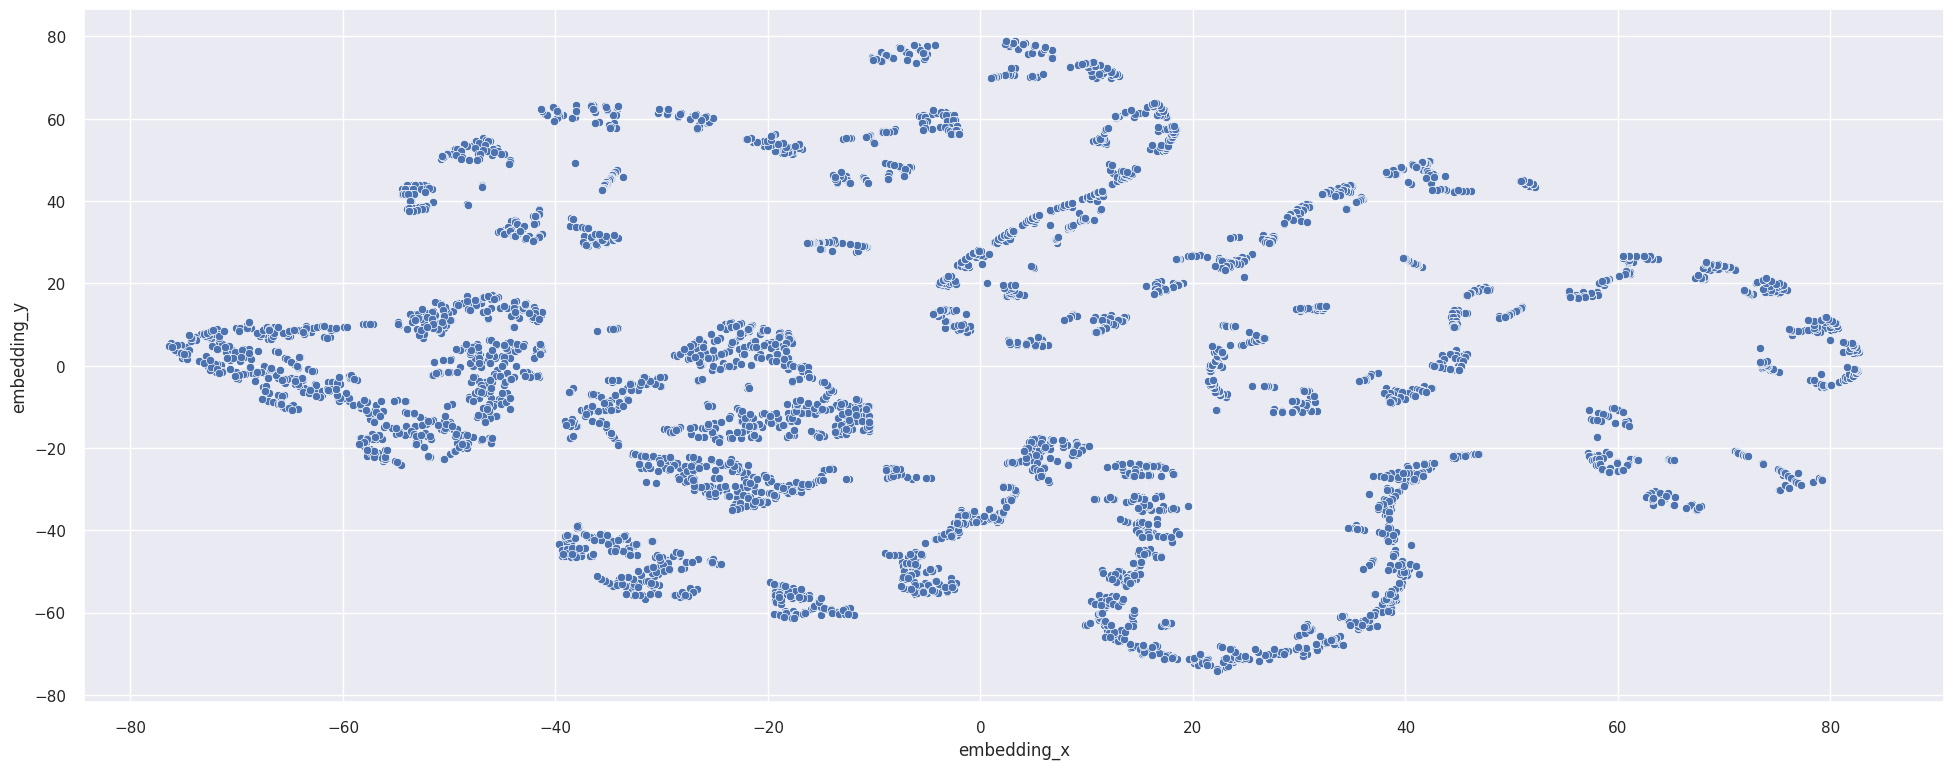

In [63]:
reducer = TSNE( n_components=2, n_jobs=-1, random_state=42 )
embedding = reducer.fit_transform( X )

# embedding
df_tsne = pd.DataFrame()
df_tsne['embedding_x'] = embedding[:, 0]
df_tsne['embedding_y'] = embedding[:, 1]

# plot TSNE
sns.scatterplot( x='embedding_x', y='embedding_y', data=df_tsne )

### 4.3.4. Tree-Based Embedding

In [64]:
from sklearn import ensemble as en

In [65]:
# training datasets

X = df43.drop( columns=['gross_revenue'], axis=1)
y = df43['gross_revenue']

# model definition
rf_model = en.RandomForestRegressor( n_estimators=100, random_state=42 )

# model training
rf_model.fit( X, y)


,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [66]:
df_leaf = pd.DataFrame( rf_model.apply(X) )

In [67]:
df_leaf.head()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87,88,89,90,91,92,93,94,95,96,97,98,99
0,6432,6884,6930,6402,6583,6823,6851,6914,6957,6502,6557,6446,6639,6802,6606,6403,6523,6699,6849,6875,6700,6782,6811,6942,6823,6857,6563,6680,6524,6644,6615,6672,6665,6544,6893,6982,6709,6948,6421,6885,6824,6521,6928,6600,6728,6529,6887,6845,6934,6978,6643,6834,6496,6437,6716,6913,6453,6635,6740,6425,6580,6835,6809,6584,6506,6920,6478,6599,6853,6941,6887,6875,6385,6497,6827,6687,6835,6531,6953,6900,6769,6812,6931,6557,6558,6824,6542,6855,6692,6537,6923,6515,6991,6719,6704,6649,6496,6541,6574,6834
1,6415,6204,6323,6316,6431,6555,6295,6076,6816,6478,6446,6336,6309,6762,6410,6350,6434,5976,6295,5974,6566,6185,6350,6350,5995,6059,6457,6584,6436,6636,6485,6557,6519,6511,6771,6823,5748,6815,6338,6063,6403,6451,6056,6470,6497,6332,6339,6296,6441,6749,6521,6381,6446,6376,6004,6768,6368,6548,6710,6370,6407,6769,6649,6552,6409,6396,6407,6524,6715,6488,6482,6266,6318,6458,6666,6598,6124,6382,6220,6297,6235,5616,6714,6429,6484,6646,6395,6814,5860,6500,6372,6378,6867,6314,6263,6355,6464,6401,6405,6625
2,5521,6456,6828,6346,6555,6770,6330,6848,6873,6897,6504,6437,6326,6793,6594,6391,6474,6762,6289,6806,6684,6211,6371,6461,6736,6743,6473,6938,6481,5674,6870,6628,6562,5553,6834,6889,6654,6849,6411,6809,5283,6479,6834,6534,6616,6471,6418,6461,6813,6714,6607,5064,6463,5661,6907,6802,6420,6552,6699,5233,6562,6815,6747,5798,6478,6373,6476,6564,6774,6869,6796,6369,6375,4976,6685,6643,6670,6517,6376,6420,6844,6716,6826,6448,6580,6733,6500,6860,6647,6495,6392,6406,6898,5709,6307,6593,6431,6378,6552,6748
3,2773,530,938,664,522,639,1066,437,460,710,1009,3404,1395,960,790,660,574,813,631,494,727,556,926,682,891,3200,415,1101,467,518,384,1096,975,445,335,357,470,1304,1067,287,773,581,1165,851,626,994,865,399,462,862,702,1383,618,257,539,928,1161,501,993,524,1299,680,1059,836,723,997,1297,755,701,954,798,2894,1492,733,996,1020,444,671,1042,740,750,359,554,735,683,3340,696,316,806,1075,1301,827,1100,504,1064,791,695,1142,510,505
4,645,2322,1583,1273,712,2399,1741,2300,2128,2049,2194,567,2125,2351,1816,1191,2363,2160,1373,1754,1133,2050,1742,2779,2601,453,1951,579,1937,828,917,2143,2260,754,1699,1947,2210,2647,2296,706,1107,665,1766,1758,458,522,2351,2273,1747,1341,1665,2171,77,1764,2331,1268,1794,654,1615,2581,2194,1548,2298,1726,1759,2875,2221,506,1125,1661,1807,611,2721,2290,1617,2473,2326,2198,2085,1768,469,2689,795,2211,2302,1108,903,705,2157,1737,2133,1618,635,1718,636,590,1717,2091,1733,2217


/home/gabri/miniconda3/envs/pa005/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/gabri/miniconda3/envs/pa005/lib/python3.10/site-packages/sklearn/manifold/_spectral_embedding.py:328: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


<Axes: xlabel='embedding_x', ylabel='embedding_y'>

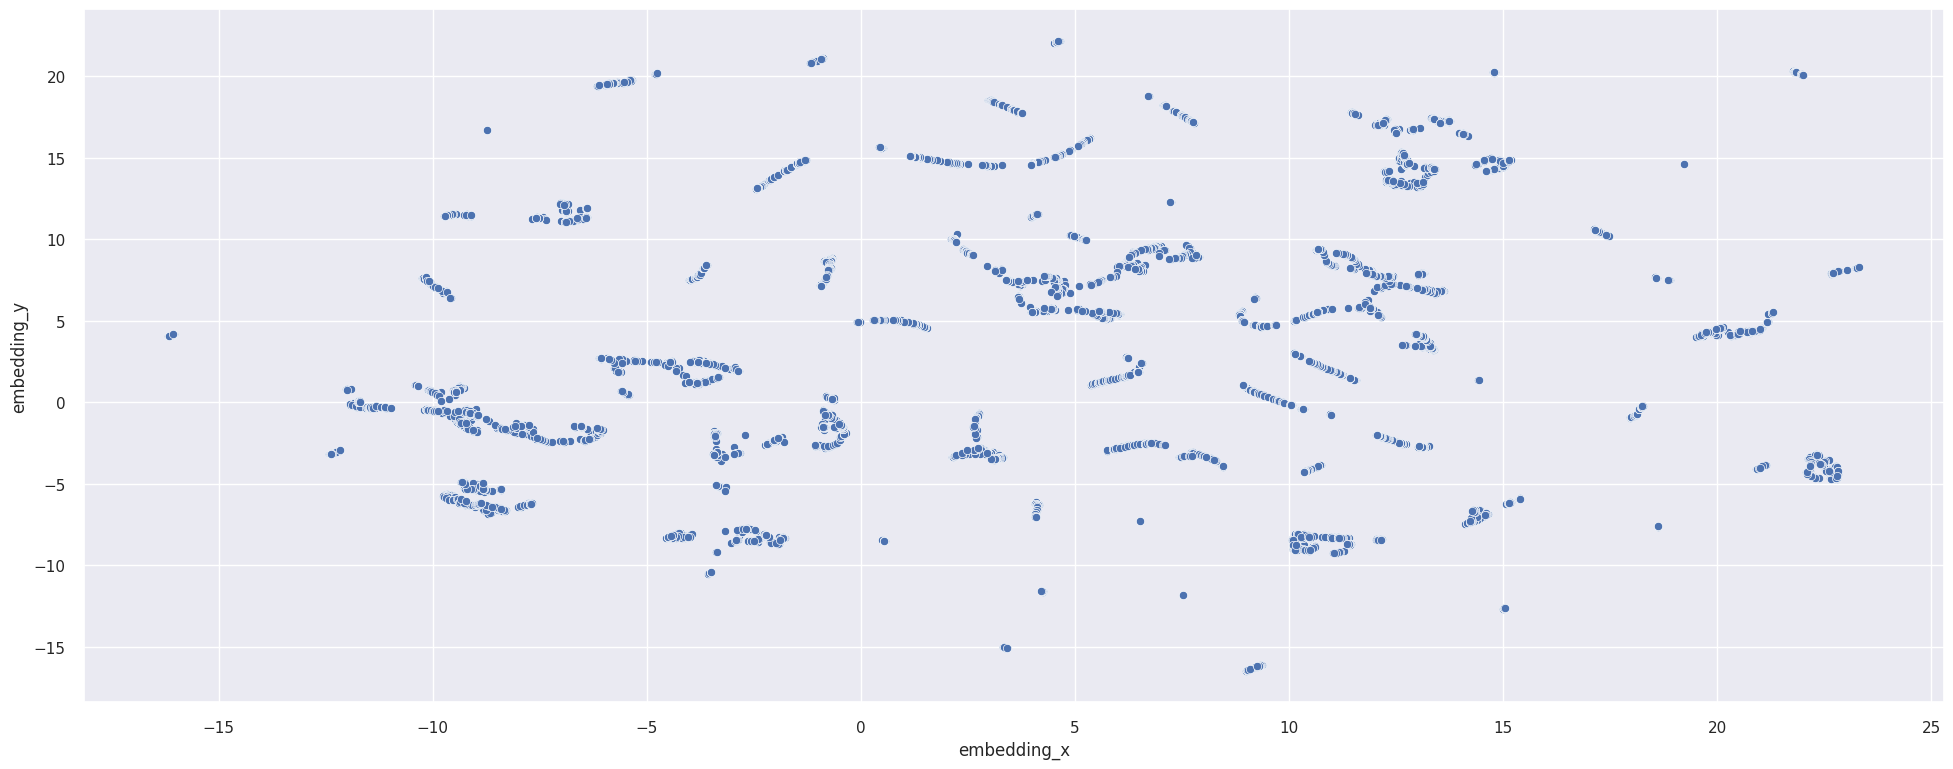

In [68]:
reducer = umap.UMAP( random_state=42 )
embedding = reducer.fit_transform( df_leaf )

# embedding
df_tree = pd.DataFrame()
df_tree['embedding_x'] = embedding[:, 0]
df_tree['embedding_y'] = embedding[:, 1]

# plot UMAP
sns.scatterplot( x='embedding_x', y='embedding_y', data=df_tree)

#  <font color='red'> 5.0. Data Preparation </font>

In [69]:
# Tree-Based Embedding
#df5 = df_tree.copy()

# TSNE Embedding
#df5 = df_tsne.copy()

# UMAP Embedding
df5 = df_umap.copy()

#  <font color='red'> 7.0. Hyperparameter Fine-Tunning </font>

In [70]:
X = df5.copy()

In [71]:
X.head()

,embedding_x,embedding_y
0,-6.185615,12.631633
1,10.887131,-0.753305
2,13.798430,15.840487
3,5.299730,1.640452
4,-2.731372,9.662052


In [72]:
# clusters = [2,3,4,5,6,7]
clusters = np.arange(2, 25, 1)

## 7.1. K-Means 

In [73]:
kmeans_list = []
for k in clusters:    
    # model definition
    kmeans_model = c.KMeans( n_clusters=k, n_init=100, random_state=42)
    
    # model training
    kmeans_model.fit( X )
    
    # model predict
    labels = kmeans_model.predict( X )
    
    # model preformance
    sil = m.silhouette_score( X, labels, metric='euclidean' )
    kmeans_list.append( sil )

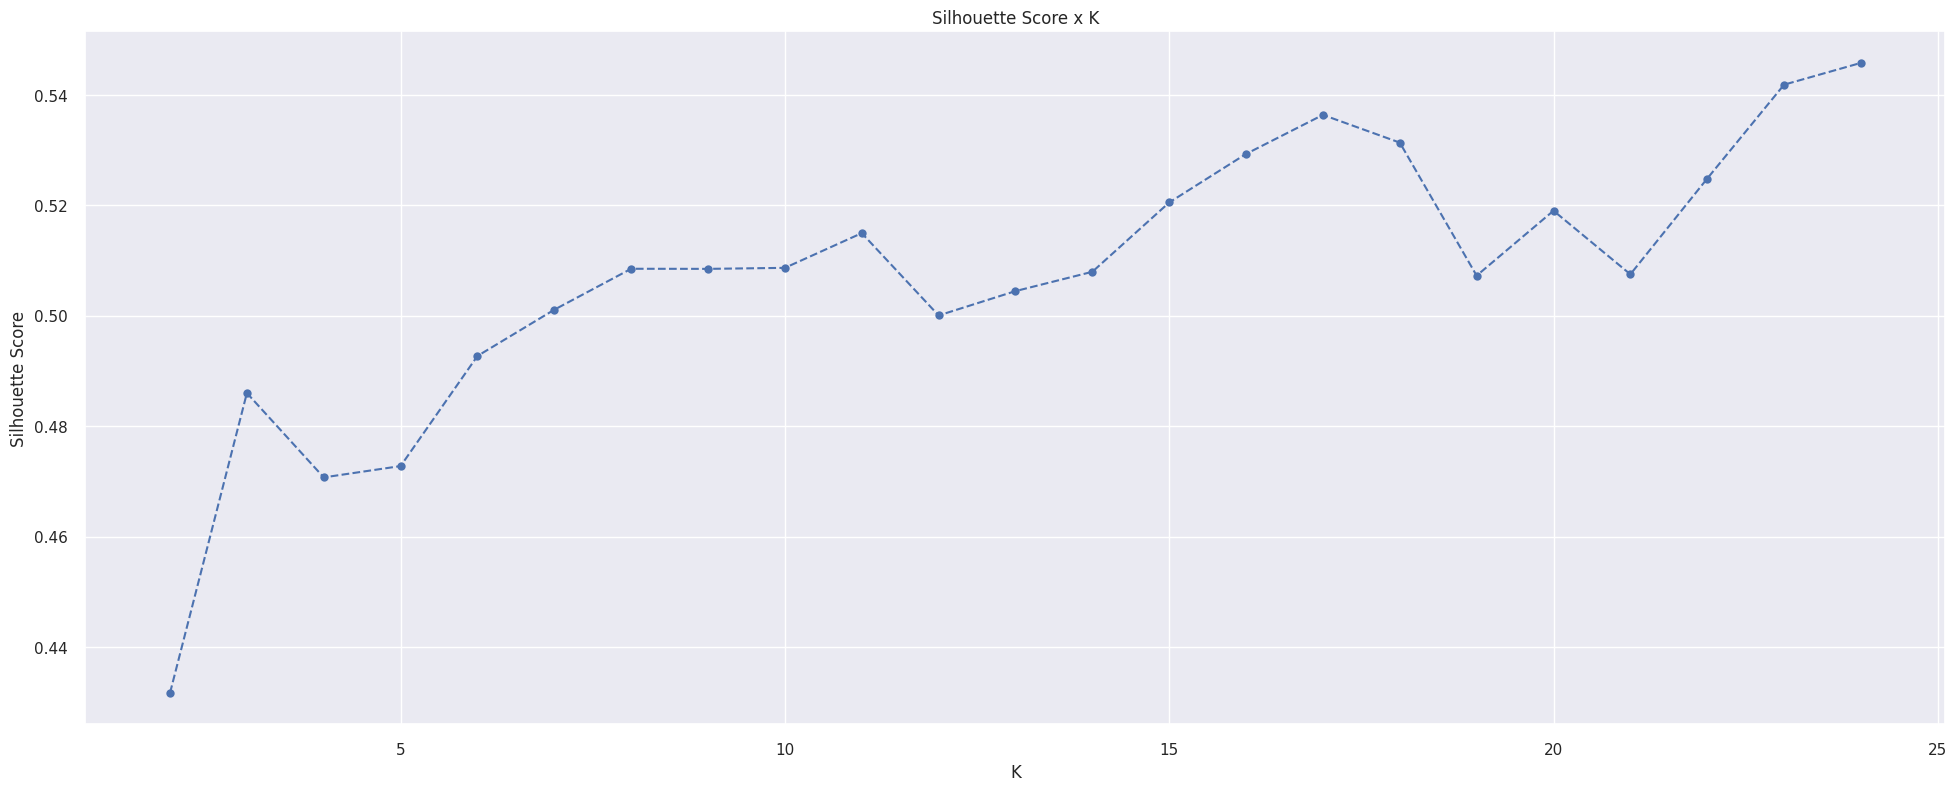

In [74]:
plt.plot( clusters, kmeans_list, linestyle='--', marker='o', color='b')
plt.xlabel( 'K' );
plt.ylabel( 'Silhouette Score' );
plt.title( 'Silhouette Score x K' );

## 7.2. GMM

In [75]:
gmm_list = []
for k in clusters:    
    # model definition
    gmm_model = mx.GaussianMixture( n_components=k, random_state=42)
    
    # model training
    gmm_model.fit( X )
    
    # model predict
    labels = gmm_model.predict( X )
    
    # model preformance
    sil = m.silhouette_score( X, labels, metric='euclidean' )
    gmm_list.append( sil )

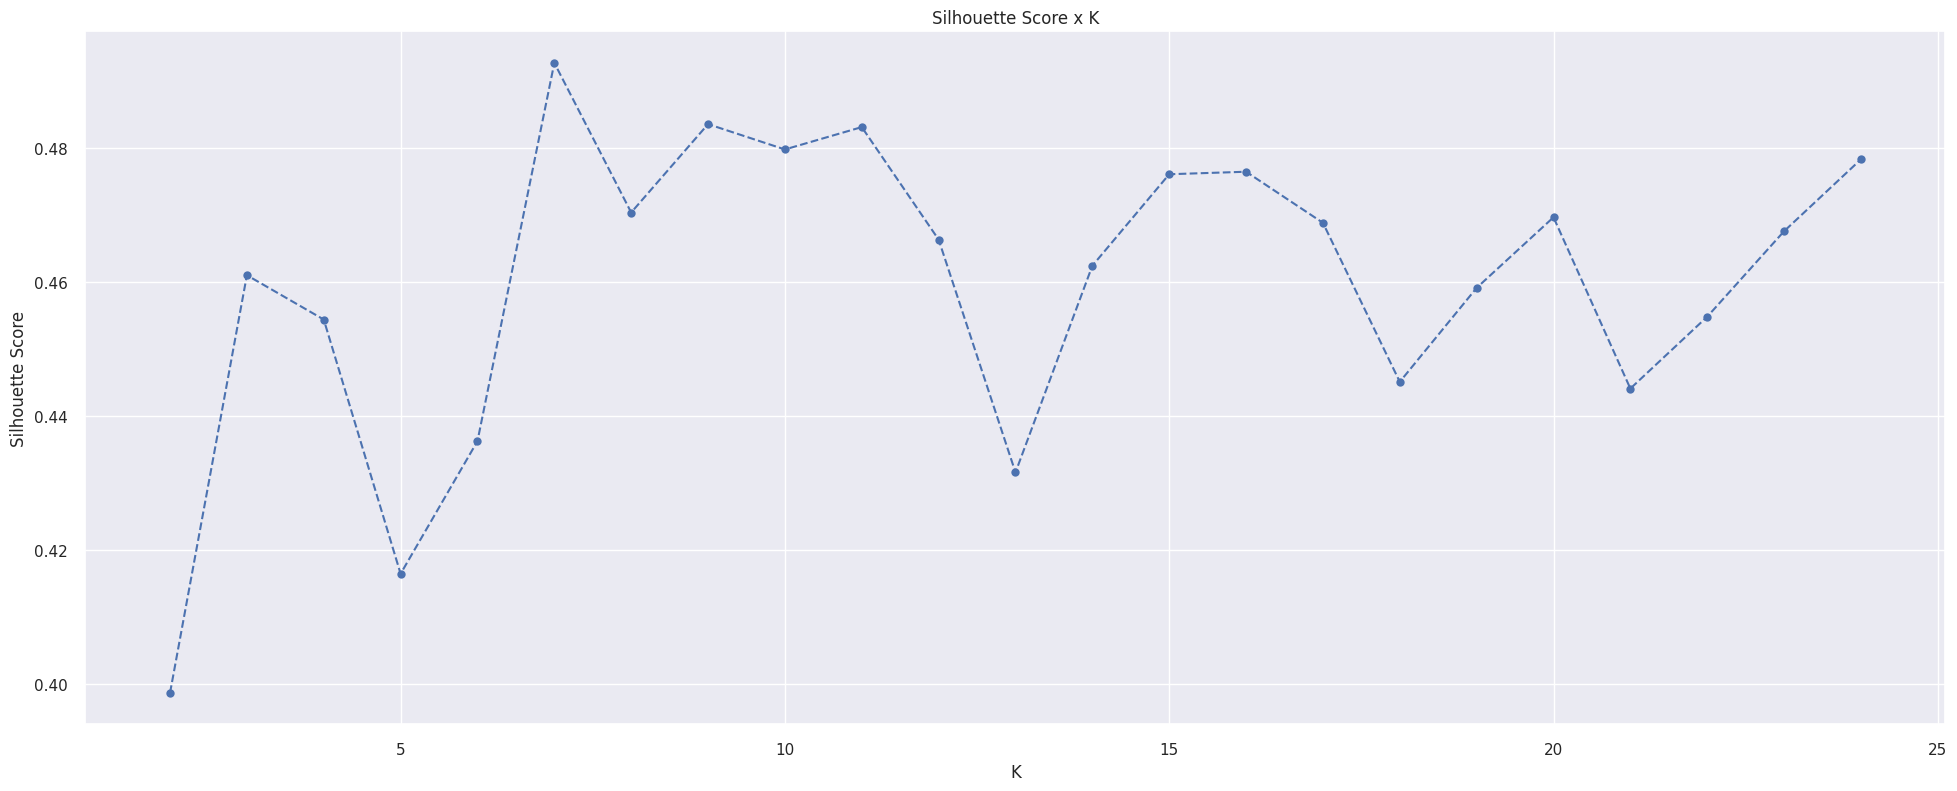

In [76]:
plt.plot( clusters, gmm_list, linestyle='--', marker='o', color='b')
plt.xlabel( 'K' );
plt.ylabel( 'Silhouette Score' );
plt.title( 'Silhouette Score x K' );

## 7.3. Hierarquical Clustering

In [77]:
# model definition and training
hc_model = hc.linkage( X, 'ward')

In [78]:
#hc.dendrogram(
#    hc_model,
#    leaf_rotation=90,
#    leaf_font_size=8    
#)

#plt.show()

In [79]:
#hc.dendrogram(
#    hc_model,
#    truncate_mode='lastp',
#    p=12,
#    leaf_rotation=90,
#    leaf_font_size=8,
#    show_contracted=True
#)

#plt.show()

### 7.3.1. HClustering Silhouette Score

In [80]:
hc_list = []
for k in clusters: 
    # model definition e training
    hc_model = hc.linkage( X, 'ward')
    
    # model predict
    labels = hc.fcluster( hc_model, k, criterion='maxclust')
    
    # model performance
    sil = m.silhouette_score( X, labels, metric='euclidean' )
    hc_list.append( sil )

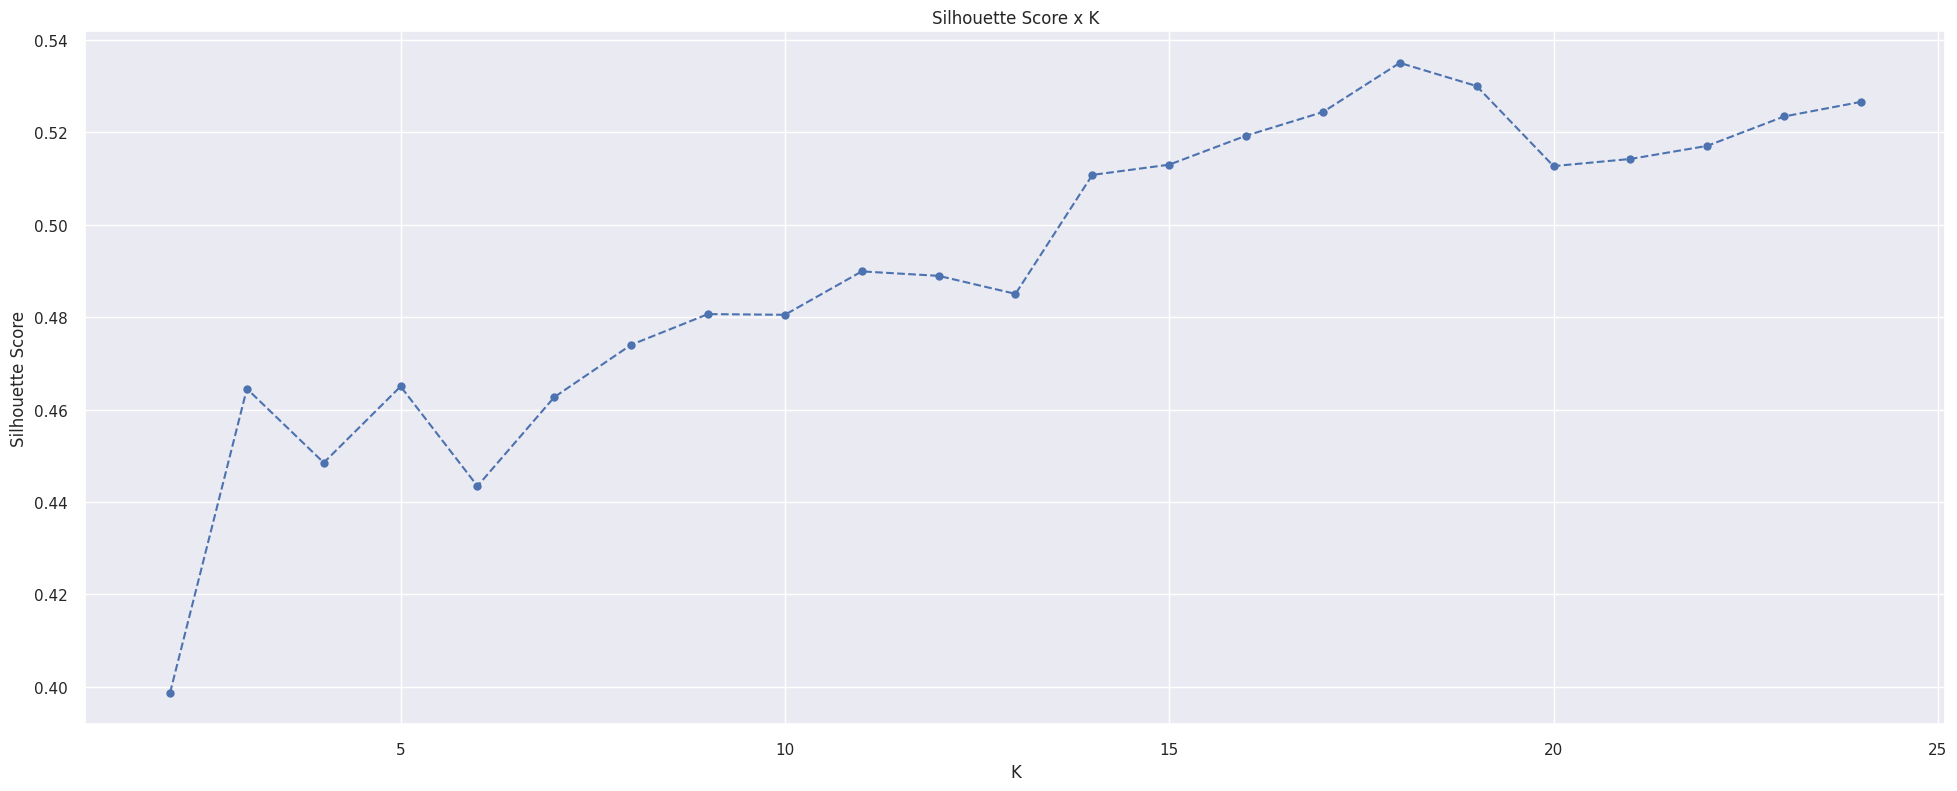

In [81]:
plt.plot( clusters, hc_list, linestyle='--', marker='o', color='b')
plt.xlabel( 'K' );
plt.ylabel( 'Silhouette Score' );
plt.title( 'Silhouette Score x K' );

## 7.4. DBSCAN

In [82]:
eps=0.5
min_samples=20

# model definition
dbscan_model = c.DBSCAN( eps=eps, min_samples=min_samples )

# model training e prediction
labels = dbscan_model.fit_predict( X )

sil = m.silhouette_score( X, labels, metric='euclidean' )
print( 'Silhouette Score: {}'.format( sil ) )
print( 'Number of Clusters: {}'.format( len( unique( labels ) ) ) )
print( unique(labels) )

Silhouette Score: 0.5124466419219971
Number of Clusters: 62
[-1  0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22
 23 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46
 47 48 49 50 51 52 53 54 55 56 57 58 59 60]


In [83]:
from sklearn.neighbors import NearestNeighbors

In [84]:
neighbors = NearestNeighbors( n_neighbors=min_samples ).fit( X )
distances, indices = neighbors.kneighbors( X )

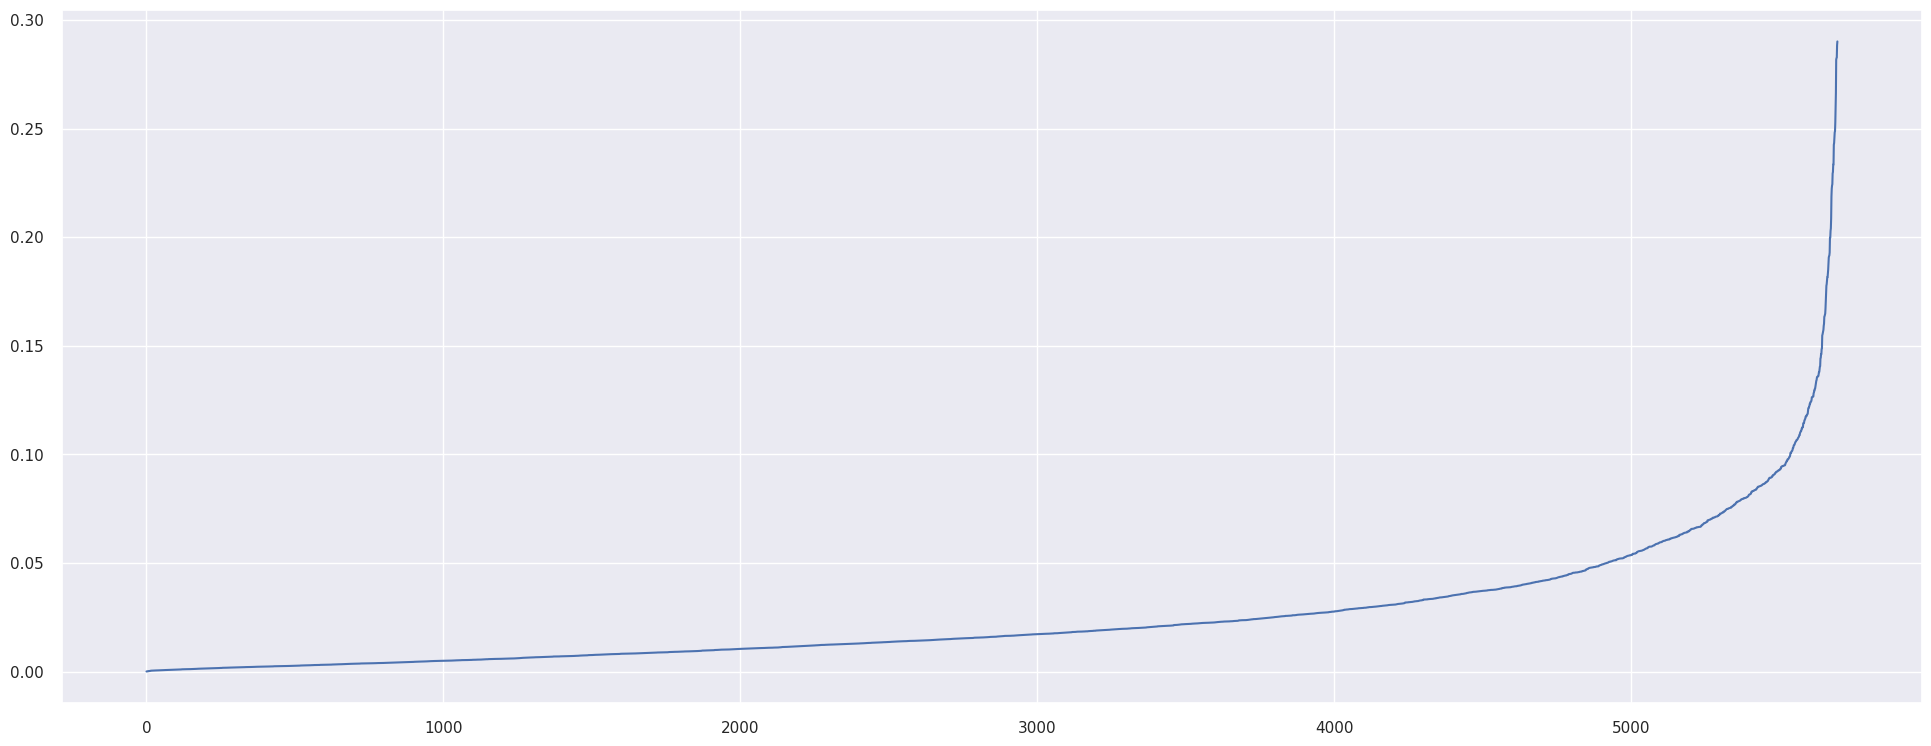

In [85]:
distances = np.sort( distances, axis=0 )
distances = distances[:,1]
plt.plot( distances )

In [86]:
dbscan_list = [0.55, 0, 0, 0, 0, 0]

## 7.5. Results - Tree Based Embedding

In [87]:
df_results = pd.DataFrame(
    {'Kmeans': kmeans_list,
    'GMM': gmm_list,
    'HC': hc_list
        }
).T

df_results.columns = clusters

In [88]:
df_results.style.highlight_max(color='lightgreen', axis=1)

,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24
Kmeans,0.431690,0.485969,0.470700,0.472752,0.492682,0.501059,0.508469,0.508451,0.508635,0.514918,0.500015,0.504425,0.507921,0.520467,0.529258,0.536327,0.531306,0.507221,0.518976,0.507466,0.524795,0.541794,0.545739
GMM,0.398671,0.461033,0.454417,0.416453,0.436261,0.492737,0.470397,0.483593,0.479813,0.483152,0.466354,0.431595,0.462447,0.476112,0.476485,0.468858,0.445114,0.459143,0.469686,0.444108,0.454839,0.467601,0.478341
HC,0.398671,0.464504,0.448502,0.465004,0.443437,0.462697,0.474022,0.480663,0.480513,0.489905,0.488942,0.485041,0.510790,0.513005,0.519282,0.524396,0.535038,0.530019,0.512696,0.514242,0.517077,0.523439,0.526597


## 7.5. Results - UMAP

In [89]:
df_results = pd.DataFrame(
    {'Kmeans': kmeans_list,
    'GMM': gmm_list,
    'HC': hc_list
        }
).T

df_results.columns = clusters

In [90]:
df_results.style.highlight_max(color='lightgreen', axis=1)

,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24
Kmeans,0.431690,0.485969,0.470700,0.472752,0.492682,0.501059,0.508469,0.508451,0.508635,0.514918,0.500015,0.504425,0.507921,0.520467,0.529258,0.536327,0.531306,0.507221,0.518976,0.507466,0.524795,0.541794,0.545739
GMM,0.398671,0.461033,0.454417,0.416453,0.436261,0.492737,0.470397,0.483593,0.479813,0.483152,0.466354,0.431595,0.462447,0.476112,0.476485,0.468858,0.445114,0.459143,0.469686,0.444108,0.454839,0.467601,0.478341
HC,0.398671,0.464504,0.448502,0.465004,0.443437,0.462697,0.474022,0.480663,0.480513,0.489905,0.488942,0.485041,0.510790,0.513005,0.519282,0.524396,0.535038,0.530019,0.512696,0.514242,0.517077,0.523439,0.526597


## 7.5. Results - TSNE

In [91]:
df_results = pd.DataFrame(
    {'Kmeans': kmeans_list,
    'GMM': gmm_list,
    'HC': hc_list
        }
).T

df_results.columns = clusters

In [92]:
df_results.style.highlight_max(color='lightgreen', axis=1)

,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24
Kmeans,0.431690,0.485969,0.470700,0.472752,0.492682,0.501059,0.508469,0.508451,0.508635,0.514918,0.500015,0.504425,0.507921,0.520467,0.529258,0.536327,0.531306,0.507221,0.518976,0.507466,0.524795,0.541794,0.545739
GMM,0.398671,0.461033,0.454417,0.416453,0.436261,0.492737,0.470397,0.483593,0.479813,0.483152,0.466354,0.431595,0.462447,0.476112,0.476485,0.468858,0.445114,0.459143,0.469686,0.444108,0.454839,0.467601,0.478341
HC,0.398671,0.464504,0.448502,0.465004,0.443437,0.462697,0.474022,0.480663,0.480513,0.489905,0.488942,0.485041,0.510790,0.513005,0.519282,0.524396,0.535038,0.530019,0.512696,0.514242,0.517077,0.523439,0.526597


In [93]:
# Algoritmos escolhidos: Embedding UMAP e Clustering KMeans:  10 clusters  SS ~ 0.53

#  <font color='red'> 8.0. Model Training </font>

## 8.1. K-Means

In [94]:
# model definition
k = 10
kmeans = c.KMeans(n_clusters=k, n_init=100,  random_state=42)
#
## model training
kmeans.fit( X )
#
## clustering
labels = kmeans.labels_

In [95]:
# model definition
#gmm_model = mx.GaussianMixture( n_components=k, random_state=42 )

# model training
#gmm_model.fit( X )

# model predict
#labels = gmm_model.predict( X ) 

In [96]:
# index of new cluster name
#idx = np.argsort( gmm_model.means_.sum(axis = 1) )
#
# new cluster label
#new_cluster_label = np.zeros_like( idx )
#
# cluster name
#cluster_name = [10, 11, 12, 13, 14, 15, 16, 17]
#
#labels = new_cluster_label[ labels ]
#new_cluster_label[idx] = cluster_name
#labels = new_cluster_label[ labels ]

## 8.2. Cluster Validation

In [97]:
from sklearn import metrics as m

## WSS (Within-cluster sum of square)
print( 'WSS value: {}'.format( kmeans.inertia_ ) )

## SS (Silhouette Score)
print( 'SS value: {}'. format( m.silhouette_score( X, labels, metric='euclidean' ) ) )

WSS value: 52204.43359375
SS value: 0.5086349248886108


#  <font color='red'> 9.0. Cluster Analysis </font>

In [98]:
X.head()

,embedding_x,embedding_y
0,-6.185615,12.631633
1,10.887131,-0.753305
2,13.798430,15.840487
3,5.299730,1.640452
4,-2.731372,9.662052


In [99]:
df9 = X.copy()
df9['cluster'] = labels

In [100]:
#df9 = df4.copy()
#df9['cluster'] = labels
df9.head()

,embedding_x,embedding_y,cluster
0,-6.185615,12.631633,4
1,10.887131,-0.753305,6
2,13.798430,15.840487,7
3,5.299730,1.640452,1
4,-2.731372,9.662052,9


## 9.1. Visualization Inspection

<Axes: xlabel='embedding_x', ylabel='embedding_y'>

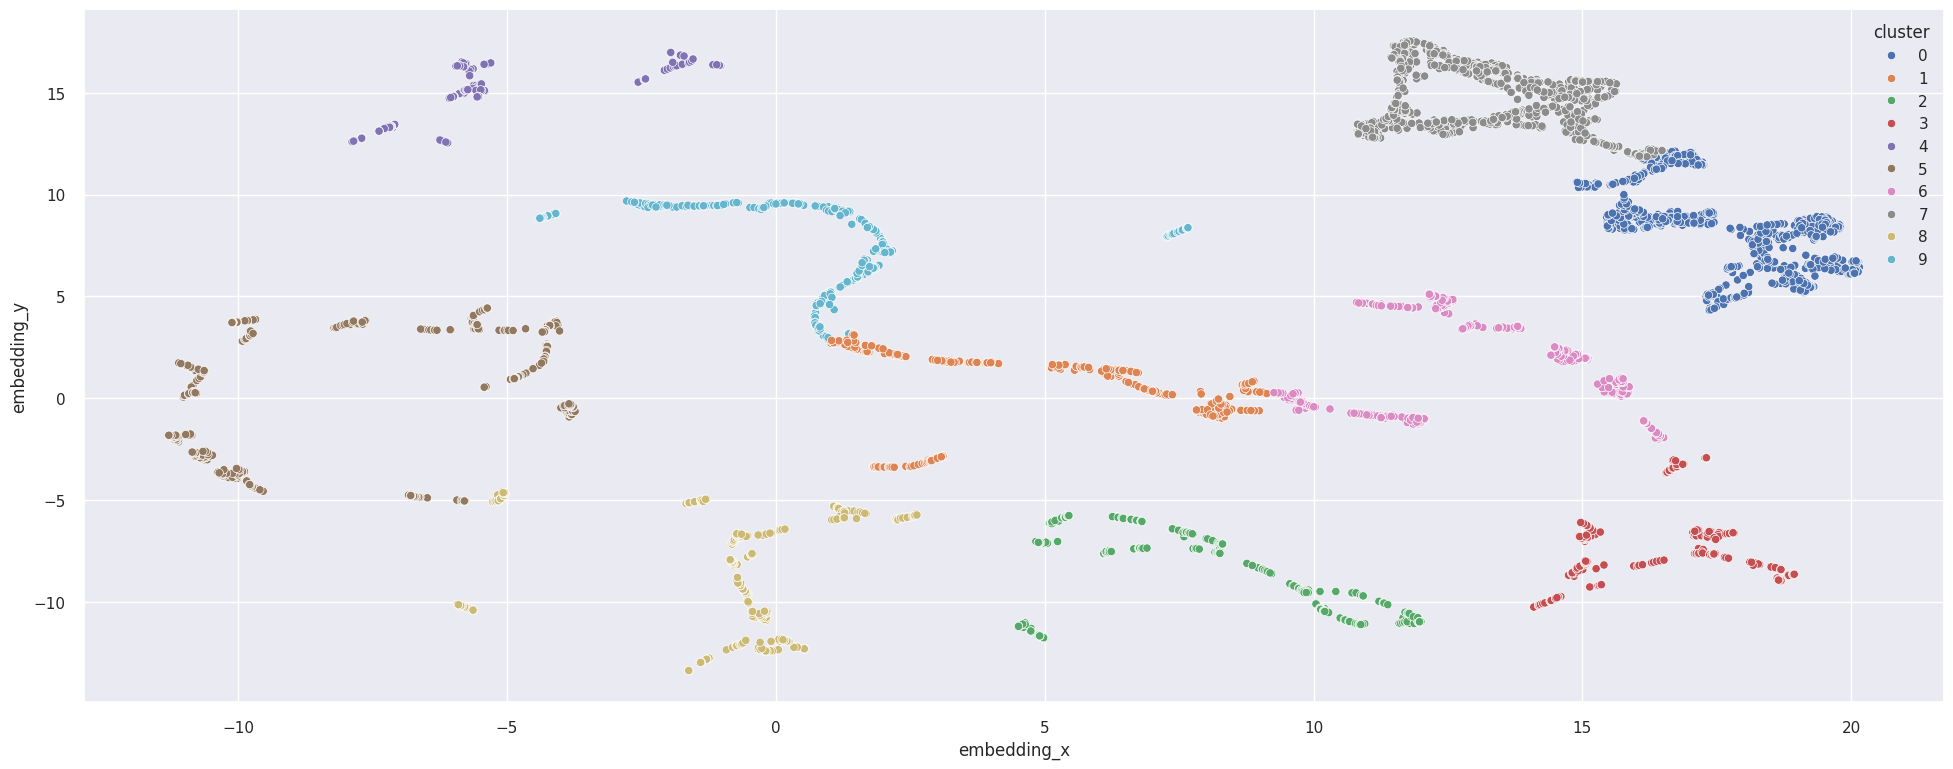

In [101]:
sns.scatterplot( x='embedding_x', y='embedding_y', hue='cluster', data=df9, palette='deep')

/home/gabri/miniconda3/envs/pa005/lib/python3.10/site-packages/sklearn/utils/validation.py:2749: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(


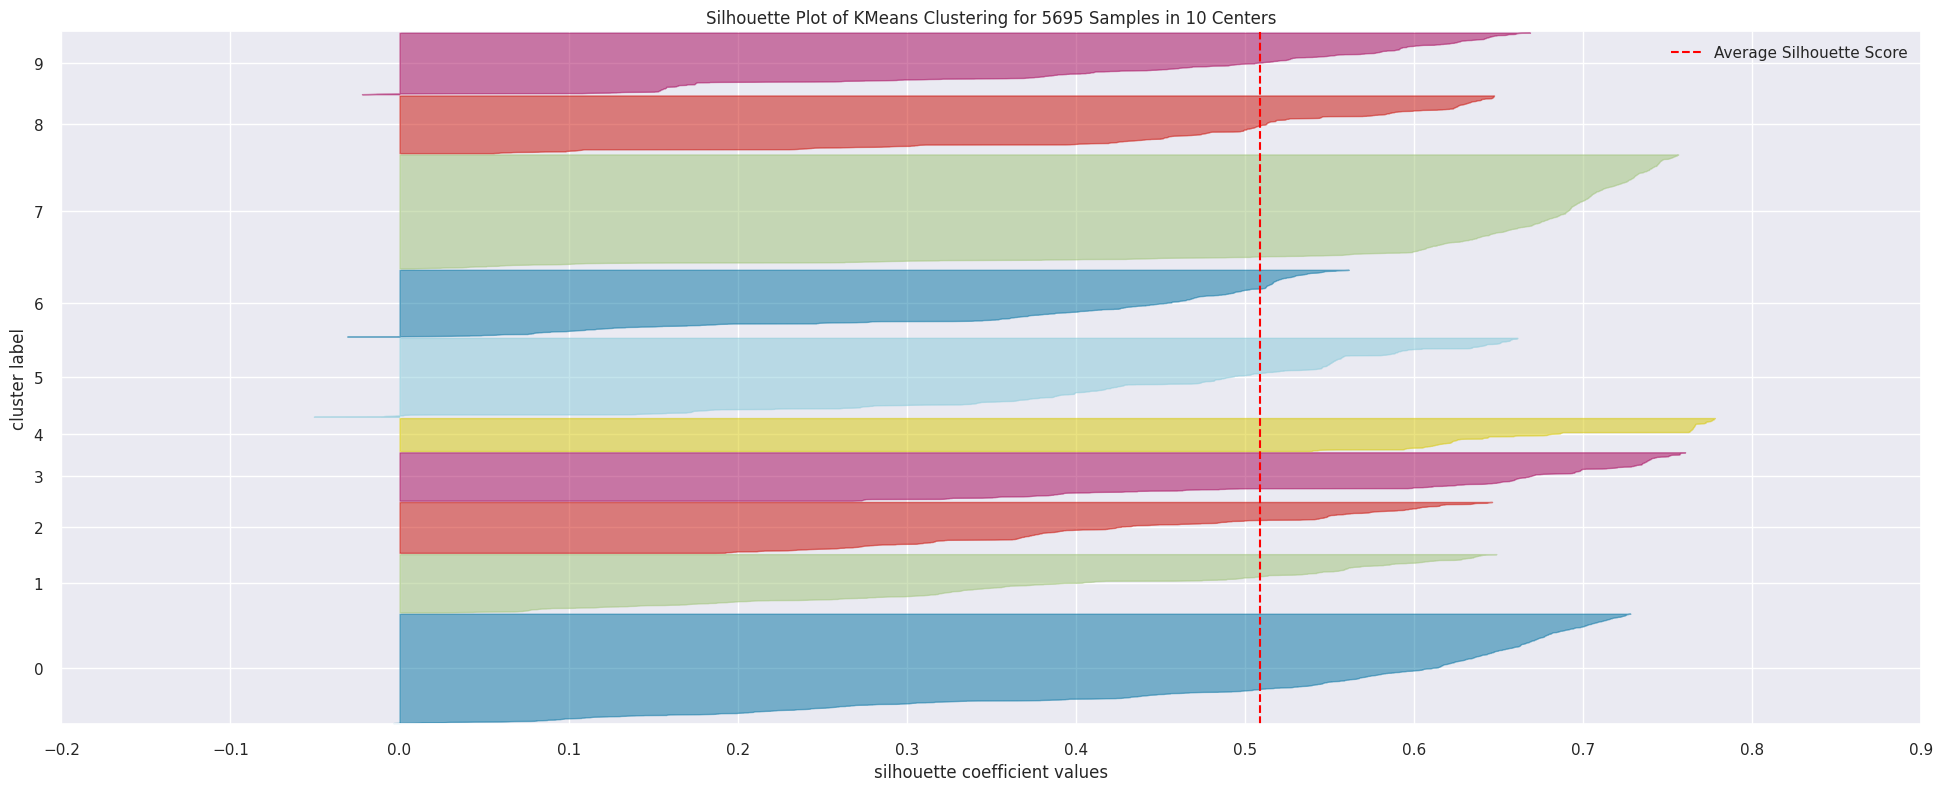

In [102]:
visualizer = SilhouetteVisualizer( kmeans, colors='yellowbrick')
visualizer.fit( X )
visualizer.finalize()

## 9.2. Cluster Profile

In [103]:
df92 = df4[ cols_selected].copy()
df92['cluster'] = labels
df92.head()

,customer_id,gross_revenue,recency_days,qtde_products,frequency,qtde_returns,cluster
0,17850,5391.21,372.0,297.0,0.486111,40.0,4
1,13047,3232.59,56.0,171.0,0.048780,35.0,6
2,12583,6705.38,2.0,232.0,0.045699,50.0,7
3,13748,948.25,95.0,28.0,0.017921,0.0,1
4,15100,876.00,333.0,3.0,0.136364,22.0,9


In [104]:
# Number of customer
df_cluster = df92[['customer_id', 'cluster']].groupby( 'cluster' ).count().reset_index()
df_cluster['perc_customer'] = 100 * (df_cluster['customer_id'] / df_cluster['customer_id'].sum())

# Avg Gross revenue
df_avg_gross_revenue = df92[['gross_revenue', 'cluster']].groupby( 'cluster' ).mean().reset_index()
df_cluster = pd.merge( df_cluster, df_avg_gross_revenue, how='inner', on='cluster')

# Avg receny days
df_avg_recency_days = df92[['recency_days', 'cluster']].groupby( 'cluster' ).mean().reset_index()
df_cluster = pd.merge( df_cluster, df_avg_recency_days, how='inner', on='cluster')

# Avg invoice no
df_avg_invoice_no= df92[['qtde_products', 'cluster']].groupby( 'cluster' ).mean().reset_index()
df_cluster = pd.merge( df_cluster, df_avg_invoice_no, how='inner', on='cluster')

# frequency
df_frequency= df92[['frequency', 'cluster']].groupby( 'cluster' ).mean().reset_index()
df_cluster = pd.merge( df_cluster, df_frequency, how='inner', on='cluster')

# returns
df_qtde_returns= df92[['qtde_returns', 'cluster']].groupby( 'cluster' ).mean().reset_index()
df_cluster = pd.merge( df_cluster, df_qtde_returns, how='inner', on='cluster')


df_cluster.sort_values(by='gross_revenue', ascending=False)

,cluster,customer_id,perc_customer,gross_revenue,recency_days,qtde_products,frequency,qtde_returns
7,7,956,16.786655,5580.131820,7.669456,231.239540,0.049893,66.250000
0,0,918,16.119403,1537.295229,31.028322,87.708061,0.047041,15.712418
1,1,489,8.586479,1434.848834,95.402863,59.214724,0.315789,165.969325
9,9,516,9.060579,1171.815097,199.800388,82.846899,0.206833,31.678295
6,6,560,9.833187,1088.365786,33.326786,51.232143,0.695136,3.633929
4,4,277,4.863916,906.624801,362.581227,65.126354,0.951756,2.472924
2,2,427,7.497805,762.046347,123.510539,68.564403,1.000585,0.025761
5,5,662,11.624232,612.900680,280.054381,58.740181,0.998489,0.025680
3,3,406,7.129061,559.875591,60.667488,46.923645,1.000000,0.061576
8,8,484,8.498683,482.343388,203.458678,41.696281,1.001377,0.074380


### Cluster 04: (Candidato a Insider)
    - Número de customers: 964 ( 16% do customers )
    - Faturamento médio: 5542
    - Recência média: 7 dias
    - Média de Produtos Comprados: 424 produtos
    - Frequência de pedidos: 0.05 compras/dia - um pedido a cada 20 dias
    - Receita em média: $ 5542,56 dólares

#  <font color='red'> 10.0. Perguntas de Negócio </font>

In [105]:
df10 = df92.copy()

In [106]:
df10[df10['cluster']==4].head()

,customer_id,gross_revenue,recency_days,qtde_products,frequency,qtde_returns,cluster
0,17850,5391.21,372.0,297.0,0.486111,40.0,4
10,18074,489.60,373.0,13.0,1.000000,0.0,4
18,13747,79.60,373.0,1.0,1.000000,0.0,4
25,12791,177.60,373.0,1.0,1.000000,0.0,4
29,17908,243.28,373.0,58.0,1.000000,0.0,4


## 1. Quem são as pessoas elegíveis para participar do programa de insider?

In [107]:
df10.loc[df10['cluster']==4, 'customer_id'].head()

0     17850
10    18074
18    13747
25    12791
29    17908
Name: customer_id, dtype: int64

## 2. Quantos clientes farão parte do grupo?

In [108]:
df10.loc[df10['cluster']==4, 'customer_id'].size

277

## 3. Quais as principais características desses clientes?

### Cluster 04: (Candidato a Insider)
    - Número de customers: 964 ( 16% do customers )
    - Faturamento médio: 5542
    - Recência média: 7 dias
    - Média de Produtos Comprados: 424 produtos
    - Frequência de pedidos: 0.05 compras/dia - um pedido a cada 20 dias
    - Receita em média: $ 5542,56 dólares

In [109]:
import scipy.stats as st

In [110]:
df_insiders = df10.loc[df10['cluster'] == 4, 'gross_revenue']

# Via Bootstrap
st.t.interval( confidence=0.95,
               df = len(df_insiders)-1,
               loc = np.mean(df_insiders),
               scale = st.sem( df_insiders)
              )

(643.0303125630978, 1170.2192903249888)

In [111]:
np.mean( df_insiders )

906.6248014440433

## 4. Qual a porcentagem de contribuição do faturamento, vinda do Insiders?

In [112]:
df_insiders_gmv = df10.loc[df10['cluster']==4, 'gross_revenue'].sum()
df_all_gmv = df10.loc[:, 'gross_revenue'].sum()

print( '% GMV from Insiders: {}'.format( df_insiders_gmv / df_all_gmv))

% GMV from Insiders: 0.024853395463885226


## 5. Qual a expectativa de faturamento desse grupo para os próximos meses?

A Clusterização foi realizada considerando os dados durante todo o período observado, sem a distinção do mês. Para ser possível obter uma expectativa mensal futura de faturamento do cluster Insiders seria necessário um desdobramento do projeto principal, no qual seria aplicada a clusterização observando os dados mensalmente através do uso de séries temporais.

## 6. Quais as condições para uma pessoa ser elegível ao Insiders?

Não é possível determinar as condições de forma objetiva, pois é o modelo de machine learning que determina internamente as condições de uma pessoa ser elegível ao Insiders. O que pode ser observado é que as pessoas do grupo Insiders tendem a gastar mais na soma de suas compras, mas outras variavés como quantidade de produtos, frequência e recência também podem influenciar uma pessoa pertencer ou não no grupo Insiders. 

## 7. Quais as condições para uma pessoa ser removida do Insiders?

Não é possível determinar as condições de forma objetiva, pois é o modelo de machine learning que determina internamente as condições de uma pessoa ser elegível ao Insiders. O que pode ser observado é que as pessoas do grupo Insiders tendem a gastar mais na soma de suas compras, mas outras variavés como quantidade de produtos, frequência e recência também podem influenciar uma pessoa pertencer ou não no grupo Insiders. 

## 8. Qual a garantia que o programa Insiders é melhor que o restante da base?

Seriam necessários testes adicionais, como testes A|B, para avaliar o resulto prático da escolha do cluster em questão. Entrentao, é possível observar que o gross revenue do cluster Insiders correspondem a 52% da receita total, contendo somente 16% do total de clientes da base.

## 9. Quais ações o time de marketing pode realizar para aumentar o faturamento?   

O primeiro passo seria analisar as principais características de cada cluster, comparando-as com as características do cluster Insiders. Em seguida estudar como aproximar cada cluster do cluster Insiders. Por fim adotar estratégias específicas para os clientes conforme os clustes que eles pertencem. 